# Pràctica 1. Què podem aprendre dels passatgers del Titanic?

**Memòria i codi.** Aprenentatge Computacional, curs 2026-2027.

**Autors i NIU:** cal completar aquesta dada abans de lliurar la pràctica.

Volem predir `Survived`: 1 si el passatger va sobreviure i 0 si no.
La pregunta no és només quin model encerta més. També volem entendre què
representen les dades, què passa quan falta informació i en quins passatgers
ens equivoquem. Una associació històrica no demostra una causa.

Seguim els cinc apartats de l'enunciat. A cada bloc expliquem la pregunta,
fem la prova i interpretem el resultat. No totes les proves han de millorar:
una prova que surt pitjor també serveix per descartar una idea.

**Protocol fixat abans de comparar:** 20% de test reservat, 5 folds
estratificats sobre el 80% restant i llavor 42. Primer comparem accuracy,
tal com demana l'enunciat. Per a la decisió final prioritzarem F1 de la classe
supervivent, perquè ens interessa equilibrar precision i recall d'aquesta
classe. És una elecció didàctica explícita, no una regla universal del Titanic.
Mantindrem també accuracy, balanced accuracy, ROC-AUC i average precision.
El llindar final serà el que porta el model per defecte; la prova de llindars
de logística serà explicativa i no modificarà el model final.

## 0. Materials que hem utilitzat

| Material de la carpeta | Idea que comprovem aquí |
|---|---|
| Pràctica 1 i notebook de primers passos | Cabina desconeguda, baseline, títol del nom |
| P1 Encoding i NaNs | No confondre absència amb zero, imputar dins de train |
| S01 i S02 | Representació de les dades, distàncies i escalat de KNN |
| P2 i S03-S04 | Error d'entrenament, generalització i regularització |
| P3 Classificació | Models de classificació i lectura dels errors |
| S05 Validació | Test separat i preprocessament dins de cada fold |
| S06 Llindars | Separar score, probabilitat i decisió |
| S07 Mètriques | Baseline, ROC/PR i errors per subgrups |
| S08 SVM | Marge, C, gamma i kernels |

Els CSV de cases, sensors i diabetis són d'altres problemes. No es barregen
amb el Titanic. Els ZIP contenen els mateixos materials descomprimits.
No tenim el llibre complet a la carpeta: les connexions es basen en els
apunts i notebooks disponibles, no en una lectura inventada del llibre.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.model_selection import cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import ParameterGrid, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance

LLAVOR = 42
TREBALLADORS = 2
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 35)
pd.set_option('display.precision', 4)

# El notebook funciona des de la seva carpeta, des de l'arrel o des de Colab.
candidats = [Path('dades/titanic_train.csv'),
             Path('solucio_practica1/dades/titanic_train.csv'),
             Path('../APC_Practica_1_2026/titanic_train.csv'),
             Path('APC_Practica_1_2026/titanic_train.csv'),
             Path('titanic_train.csv')]
fitxer = None
for candidat in candidats:
    if candidat.exists():
        fitxer = candidat
        break
if fitxer is None:
    raise FileNotFoundError('Cal posar titanic_train.csv al costat del notebook o a dades/.')

sortida = Path('resultats')
sortida.mkdir(exist_ok=True)
(sortida / 'grafics').mkdir(exist_ok=True)

def guardar_grafic(nom):
    plt.tight_layout()
    plt.savefig(sortida / 'grafics' / (nom + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def comentar(text):
    display(Markdown(text))

versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__}
print('Versions:', versions)
dades = pd.read_csv(fitxer)
empremta = hashlib.sha256(fitxer.read_bytes()).hexdigest()
print('SHA256 del CSV:', empremta)
print('Files i columnes:', dades.shape)
display(dades.head())

Versions: {'python': '3.13.3', 'numpy': '2.2.1', 'pandas': '2.3.3', 'scikit-learn': '1.7.2'}
SHA256 del CSV: 4a437fde05fe5264e1701a7387ac6fb75393772ba38bb2c9c566405af5af4bd7
Files i columnes: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. EDA: entendre les files abans d'entrenar

### 1.1. Què vol dir cada columna?

Cada fila és un passatger del conjunt d'entrenament proporcionat. No són tots
els passatgers del vaixell i no hi ha una columna de data. Tenim 12 columnes:
el target i 11 atributs originals; això no vol dir que els 11 siguin útils.

| Columna | Significat | Tipus conceptual i decisió |
|---|---|---|
| PassengerId | Identificador del registre | Identificador; exclòs de X |
| Survived | Supervivència observada | Target binari, 0/1 |
| Pclass | Classe del bitllet, 1/2/3 | Categòrica ordinal; comparem codificacions |
| Name | Nom i tractament | Text; n'extraiem el títol |
| Sex | Sexe registrat | Categoria binària del fitxer |
| Age | Edat en anys | Numèrica; els decimals poden representar infants |
| SibSp | Germans/germanes i cònjuge a bord | Recompte, no total de parents |
| Parch | Pares/mares i fills/filles a bord | Recompte |
| Ticket | Codi de bitllet | Identificador compartit per alguns passatgers |
| Fare | Tarifa registrada | Numèrica; pot correspondre a bitllets compartits |
| Cabin | Cabina registrada | Text amb molts desconeguts |
| Embarked | Port C, Q o S | Categoria nominal, sense ordre numèric |

Un `int64` no implica una magnitud: restar identificadors no mesura similitud.
Tampoc assumim que la distància social entre primera i segona classe sigui
igual que entre segona i tercera. Per això la base fa one-hot de Pclass.

Fem una auditoria general d'esquema i nuls, i separem el test abans de les
associacions amb el target. Els gràfics exploratoris següents són de desenvolupament.

In [2]:
auditoria = pd.DataFrame({'tipus_python': dades.dtypes.astype(str),
                          'nuls': dades.isna().sum(),
                          'percentatge_nuls': dades.isna().mean() * 100,
                          'valors_diferents': dades.nunique()})
display(auditoria)
print('Files exactament duplicades:', dades.duplicated().sum())
print('Identificadors repetits:', dades['PassengerId'].duplicated().sum())
assert dades['PassengerId'].is_unique
assert dades['Survived'].isin([0, 1]).all()
assert dades['Survived'].notna().all()
assert dades['Age'].dropna().between(0, 110).all()
assert (dades['Fare'].dropna() >= 0).all()

desenvolupament, test_reservat = train_test_split(
    dades, test_size=0.20, stratify=dades['Survived'], random_state=LLAVOR)
desenvolupament = desenvolupament.copy()
test_reservat = test_reservat.copy()
assert set(desenvolupament.index).isdisjoint(test_reservat.index)
print('Desenvolupament:', len(desenvolupament), 'Test reservat:', len(test_reservat))
particions = pd.DataFrame({'PassengerId': dades['PassengerId'], 'particio': 'desenvolupament'})
particions.loc[test_reservat.index, 'particio'] = 'test'
particions.to_csv(sortida / 'particions.csv', index=False)
eda = desenvolupament.copy()

,tipus_python,nuls,percentatge_nuls,valors_diferents
PassengerId,int64,0,0.0000,891
Survived,int64,0,0.0000,2
Pclass,int64,0,0.0000,3
Name,object,0,0.0000,891
Sex,object,0,0.0000,2
Age,float64,177,19.8653,88
SibSp,int64,0,0.0000,7
Parch,int64,0,0.0000,7
Ticket,object,0,0.0000,681
Fare,float64,0,0.0000,248


Files exactament duplicades: 0
Identificadors repetits: 0
Desenvolupament: 712 Test reservat: 179


### 1.2. Target i desequilibri

Comprovem si una accuracy aparentment bona es pot obtenir sense mirar cap
atribut. El desequilibri és moderat; no el tractarem com un cas d'1% de positius.
Afegim recompte i proporció perquè un percentatge sense denominador enganya.

,passatgers,proporcio
Survived,,
0,439,0.6166
1,273,0.3834


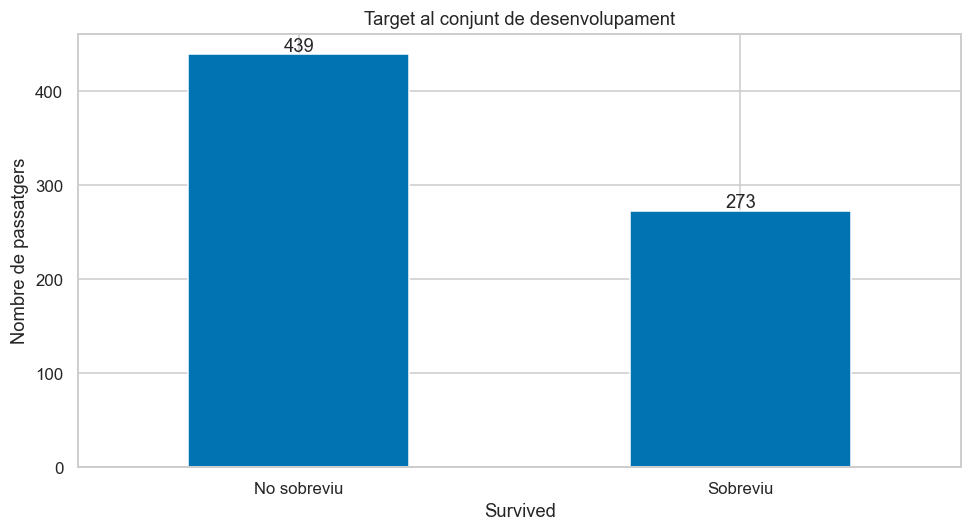

La classe majoritària ocupa el **61.7%**. Aquesta és la referència mínima: predir sempre 0 pot encertar bastant, però el seu recall de supervivents serà zero.

In [3]:
target = eda['Survived'].value_counts().sort_index()
display(pd.DataFrame({'passatgers': target, 'proporcio': target / len(eda)}))
ax = target.rename(index={0: 'No sobreviu', 1: 'Sobreviu'}).plot.bar(rot=0)
ax.set(ylabel='Nombre de passatgers', title='Target al conjunt de desenvolupament')
for i, valor in enumerate(target):
    ax.text(i, valor + 3, str(valor), ha='center')
guardar_grafic('01_target')
comentar(f"La classe majoritària ocupa el **{target.max()/len(eda):.1%}**. "
         'Aquesta és la referència mínima: predir sempre 0 pot encertar bastant, '
         'però el seu recall de supervivents serà zero.')

### 1.3. Qui sobreviu més en aquesta mostra?

Mirem sexe, classe, port i mida familiar. Els gràfics mostren associacions,
no efectes causals. Per exemple, el port pot estar relacionat amb la classe
i la tarifa. Una taxa alta amb tres persones és molt menys estable que amb 200.

,count,mean
Sex,,
female,253,0.7431
male,459,0.1852


,count,mean
Pclass,,
1,171,0.6491
2,150,0.4467
3,391,0.2430


,count,mean
Embarked,,
C,139,0.5612
Q,55,0.4364
S,516,0.3275


,count,mean
MidaFamilia,,
1,434,0.2995
2,129,0.5504
3,77,0.6234
4,22,0.7273
5,14,0.2143
6,16,0.0625
7,11,0.3636
8,4,0.0000
11,5,0.0000


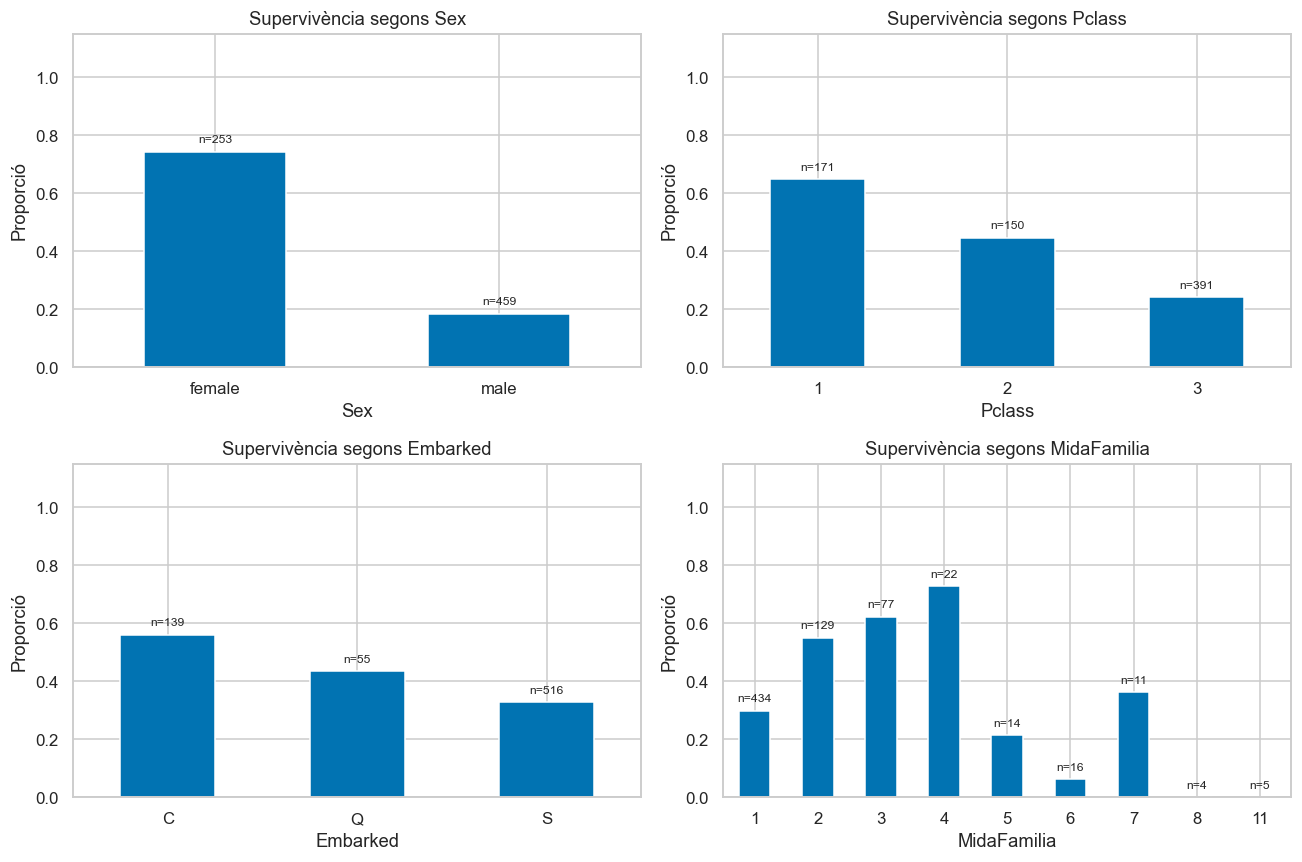

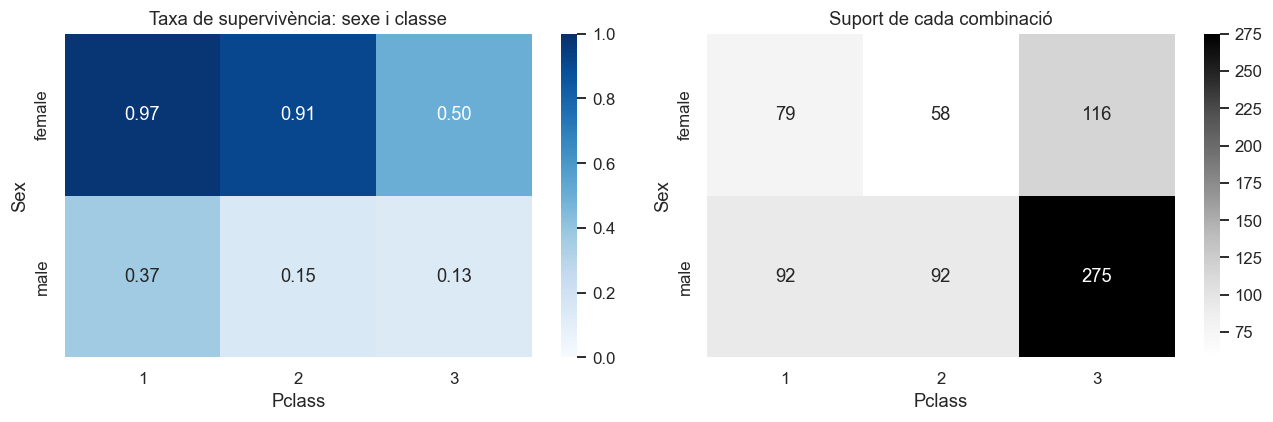

En desenvolupament sobreviuen el **74.3% de les dones** i el **18.5% dels homes**. A primera classe la taxa és 64.9%, i a tercera 24.3%. El creuament evita quedar-nos només amb dues mitjanes globals. Són patrons del registre històric; no una justificació per valorar persones de manera diferent.

In [4]:
eda['MidaFamilia'] = eda['SibSp'] + eda['Parch'] + 1
eda['CabinaConeguda'] = eda['Cabin'].notna().astype(int)
eda['EdatDesconeguda'] = eda['Age'].isna().astype(int)
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for columna, ax in zip(['Sex', 'Pclass', 'Embarked', 'MidaFamilia'], eixos.flat):
    taula = eda.groupby(columna)['Survived'].agg(['count', 'mean'])
    display(taula)
    taula['mean'].plot.bar(ax=ax, rot=0)
    ax.set(title='Supervivència segons ' + columna, ylabel='Proporció', ylim=(0, 1.15))
    for posicio, nombre in enumerate(taula['count']):
        ax.text(posicio, taula['mean'].iloc[posicio] + 0.03, 'n=' + str(nombre), ha='center', fontsize=8)
guardar_grafic('02_taxa_per_grups')

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
taxes = eda.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean')
comptes = pd.crosstab(eda['Sex'], eda['Pclass'])
sns.heatmap(taxes, annot=True, fmt='.2f', vmin=0, vmax=1, ax=eixos[0], cmap='Blues')
eixos[0].set_title('Taxa de supervivència: sexe i classe')
sns.heatmap(comptes, annot=True, fmt='d', ax=eixos[1], cmap='Greys')
eixos[1].set_title('Suport de cada combinació')
guardar_grafic('03_sexe_classe')
taxes_sexe = eda.groupby('Sex')['Survived'].mean()
taxes_classe = eda.groupby('Pclass')['Survived'].mean()
comentar(f"En desenvolupament sobreviuen el **{taxes_sexe['female']:.1%} de les dones** "
         f"i el **{taxes_sexe['male']:.1%} dels homes**. A primera classe la taxa és "
         f"{taxes_classe.loc[1]:.1%}, i a tercera {taxes_classe.loc[3]:.1%}. "
         'El creuament evita quedar-nos només amb dues mitjanes globals. '
         'Són patrons del registre històric; no una justificació per valorar persones de manera diferent.')

### 1.4. Edat, tarifa i valors extrems

La tarifa té una cua llarga. Fem també log(1 + tarifa) per veure els valors
baixos sense perdre els alts. No eliminem automàticament un passatger ric ni
un infant: un valor extrem pot ser real i informatiu. Zero euros tampoc és
necessàriament un valor perdut. No tenim informació per corregir-lo a mà.

,Age,Fare,SibSp,Parch
count,575.0000,712.0000,712.0000,712.0000
mean,29.8077,31.8198,0.4930,0.3904
std,14.4852,48.0591,1.0607,0.8381
min,0.4200,0.0000,0.0000,0.0000
25%,21.0000,7.8958,0.0000,0.0000
50%,28.5000,14.4542,0.0000,0.0000
75%,39.0000,31.0000,1.0000,0.0000
max,80.0000,512.3292,8.0000,6.0000


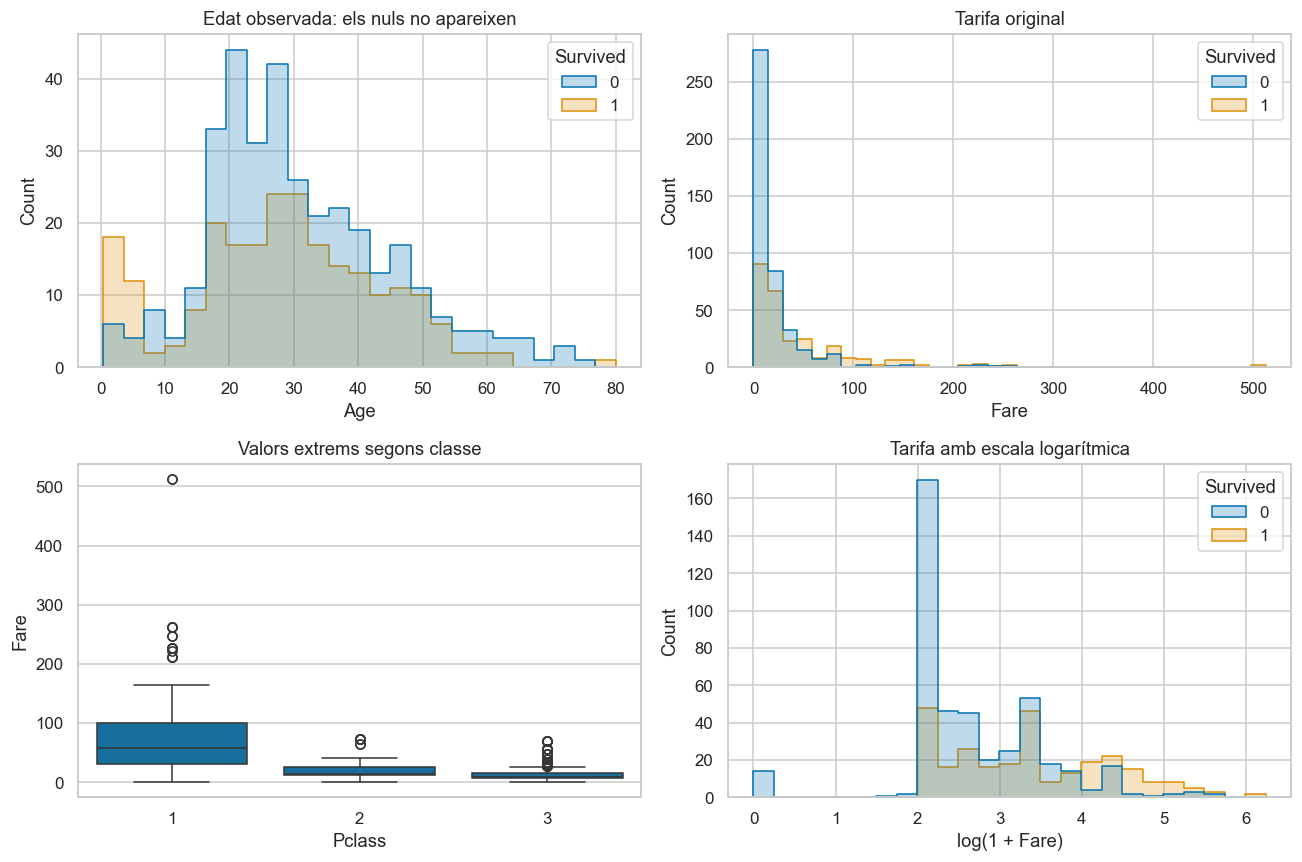

Tarifes zero: 14


In [5]:
display(eda[['Age', 'Fare', 'SibSp', 'Parch']].describe())
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(data=eda, x='Age', hue='Survived', bins=25, element='step', ax=eixos[0, 0])
eixos[0, 0].set_title('Edat observada: els nuls no apareixen')
sns.histplot(data=eda, x='Fare', hue='Survived', bins=35, element='step', ax=eixos[0, 1])
eixos[0, 1].set_title('Tarifa original')
sns.boxplot(data=eda, x='Pclass', y='Fare', ax=eixos[1, 0])
eixos[1, 0].set_title('Valors extrems segons classe')
sns.histplot(x=np.log1p(eda['Fare']), hue=eda['Survived'], bins=25, element='step', ax=eixos[1, 1])
eixos[1, 1].set(xlabel='log(1 + Fare)', title='Tarifa amb escala logarítmica')
guardar_grafic('04_edat_tarifa')
print('Tarifes zero:', int((eda['Fare'] == 0).sum()))

### 1.5. Què significa no tenir cabina apuntada?

Un buit de Cabin vol dir «no coneixem la cabina», no «no tenia cabina».
Comprovem si l'absència es relaciona amb la classe i amb la supervivència.
Aquesta prova ve directament del notebook inicial de la pràctica.

,count,mean
CabinaConeguda,,
0,552,0.2917
1,160,0.7000


count    mean
Pclass CabinaConeguda               
1      0                  35  0.4571
       1                 136  0.6985
2      0                 135  0.4074
       1                  15  0.8000
3      0                 382  0.2356
       1                   9  0.5556

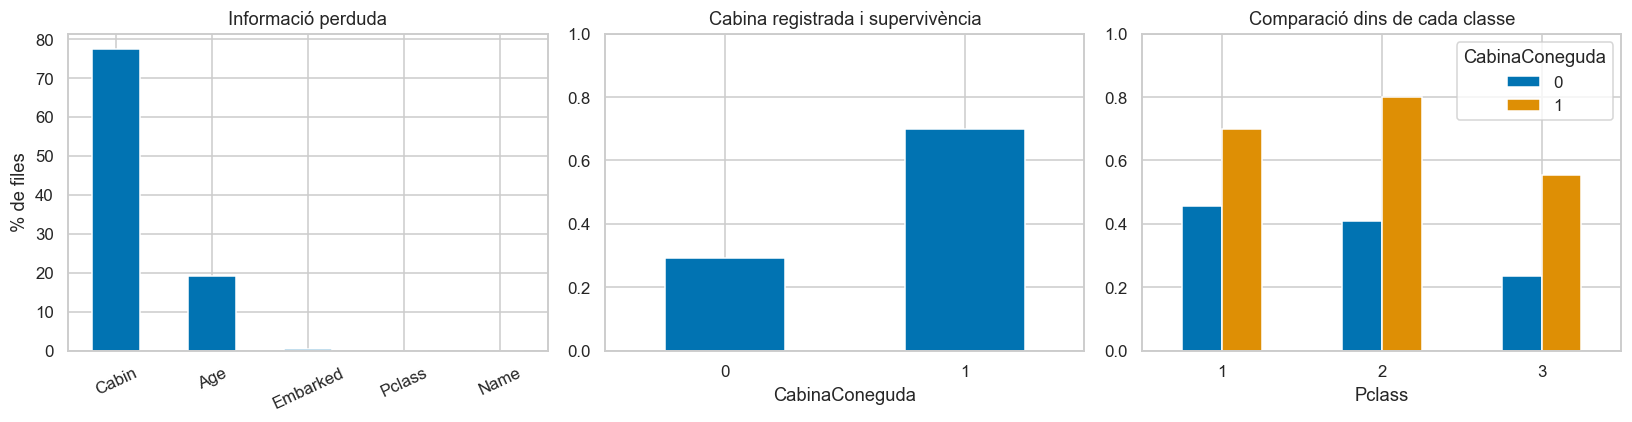

CabinaConeguda,0,1
Pclass,,
1,0.2047,0.7953
2,0.9000,0.1000
3,0.9770,0.0230


,count,mean
EdatDesconeguda,,
0,575,0.4052
1,137,0.2920


Amb cabina registrada, la taxa és 70.0%; sense cabina registrada, 29.2%. Aquesta diferència justifica provar un indicador de presència. La taula per classe mostra que cal controlar la composició dels grups. No podem demostrar que els nuls siguin aleatoris ni que conèixer la cabina causi supervivència.

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
eda.isna().mean().mul(100).sort_values(ascending=False).head(5).plot.bar(ax=eixos[0], rot=25)
eixos[0].set(title='Informació perduda', ylabel='% de files')
taula_cabina = eda.groupby('CabinaConeguda')['Survived'].agg(['count', 'mean'])
display(taula_cabina)
taula_cabina['mean'].plot.bar(ax=eixos[1], rot=0)
eixos[1].set(title='Cabina registrada i supervivència', ylim=(0, 1))
cabina_classe = eda.groupby(['Pclass', 'CabinaConeguda'])['Survived'].agg(['count', 'mean'])
display(cabina_classe)
cabina_classe['mean'].unstack().plot.bar(ax=eixos[2], rot=0)
eixos[2].set(title='Comparació dins de cada classe', ylim=(0, 1))
guardar_grafic('05_nuls_i_cabina')
display(pd.crosstab(eda['Pclass'], eda['CabinaConeguda'], normalize='index'))
display(eda.groupby('EdatDesconeguda')['Survived'].agg(['count', 'mean']))
comentar(f"Amb cabina registrada, la taxa és {taula_cabina.loc[1, 'mean']:.1%}; "
         f"sense cabina registrada, {taula_cabina.loc[0, 'mean']:.1%}. "
         'Aquesta diferència justifica provar un indicador de presència. '
         'La taula per classe mostra que cal controlar la composició dels grups. '
         'No podem demostrar que els nuls siguin aleatoris ni que conèixer la cabina causi supervivència.')

### 1.6. Correlacions i límits

Pearson resumeix relacions lineals. Spearman compara rangs i ajuda amb la
tarifa asimètrica. Cap de les dues detecta totes les interaccions. Afegim
`Dona` només per llegir aquesta matriu; al model farem one-hot.
No posem codis arbitraris de port ni identificadors a la correlació.

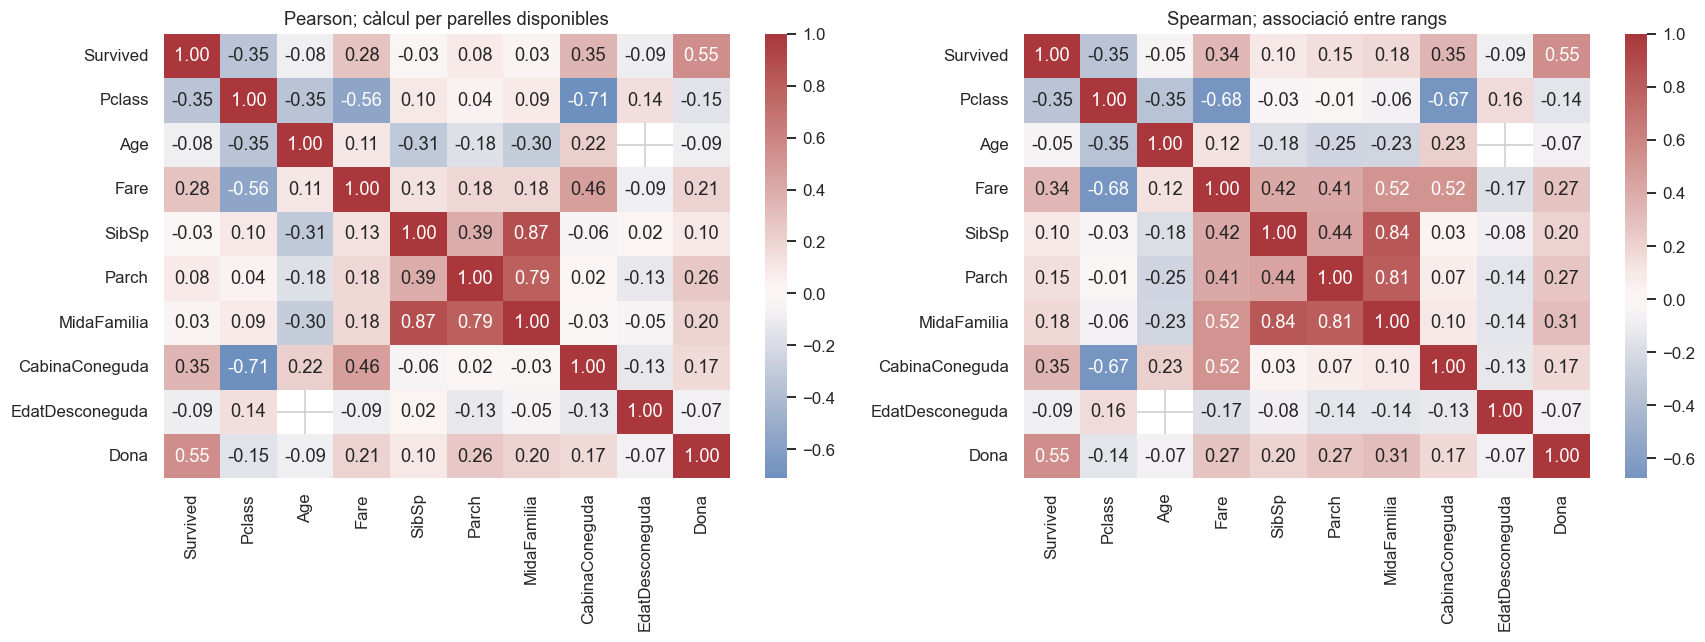

**Lectura de l’EDA.** Sexe i classe separen grups amb taxes diferents. Tarifa i cabina també poden recollir part de la informació de classe. Una correlació baixa d’edat no prova que l’edat sigui inútil: pot importar de manera no lineal o en combinació amb el sexe. Per això compararem models lineals amb models que poden representar interaccions.

In [7]:
correlacions = eda[['Survived', 'Pclass', 'Age', 'Fare', 'SibSp', 'Parch',
                    'MidaFamilia', 'CabinaConeguda', 'EdatDesconeguda']].copy()
correlacions['Dona'] = (eda['Sex'] == 'female').astype(int)
fig, eixos = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(correlacions.corr(), annot=True, fmt='.2f', center=0, cmap='vlag', ax=eixos[0])
eixos[0].set_title('Pearson; càlcul per parelles disponibles')
sns.heatmap(correlacions.corr(method='spearman'), annot=True, fmt='.2f', center=0, cmap='vlag', ax=eixos[1])
eixos[1].set_title('Spearman; associació entre rangs')
guardar_grafic('06_correlacions')
comentar('**Lectura de l’EDA.** Sexe i classe separen grups amb taxes diferents. '
         'Tarifa i cabina també poden recollir part de la informació de classe. '
         'Una correlació baixa d’edat no prova que l’edat sigui inútil: pot importar '
         'de manera no lineal o en combinació amb el sexe. Per això compararem '
         'models lineals amb models que poden representar interaccions.')

## 2. Preprocessament: decisions i experiments controlats

Base: Age, Fare, SibSp i Parch numèriques; Sex, Pclass i Embarked categòriques.
Age s'omple amb mediana i Embarked amb moda apreses **dins de cada fold**.
StandardScaler resta la mitjana i divideix per la desviació; MinMax usa el
rang; RobustScaler usa mediana i rang interquartílic. Els arbres no necessiten
distàncies comparables. Per KNN, logística regularitzada i SVM sí que provem escala.

One-hot evita inventar un ordre per a Sex i Embarked. Desconeixements en
categories noves es toleren amb `handle_unknown='ignore'`. No fem target encoding.
`Pipeline` aquí no és per complicar el codi: impedeix calcular la mediana o
l'escalat amb les files que després utilitzarem per validar.

Creem també variables amb regles fixes per fila: mida familiar, viatjar sol,
cabina coneguda, edat desconeguda, log de tarifa i títol del nom. No comptem
supervivents de la família ni fem servir etiquetes d'altres passatgers.

In [8]:
def crear_variables(taula):
    nova = taula.copy()
    nova['MidaFamilia'] = nova['SibSp'] + nova['Parch'] + 1
    nova['Sol'] = (nova['MidaFamilia'] == 1).astype(int)
    nova['CabinaConeguda'] = nova['Cabin'].notna().astype(int)
    nova['EdatDesconeguda'] = nova['Age'].isna().astype(int)
    nova['LogTarifa'] = np.log1p(nova['Fare'])
    # El tractament està entre la coma i el punt: "Cognom, Mr. Nom".
    nova['Titol'] = nova['Name'].str.split(',').str[1].str.split('.').str[0].str.strip()
    nova['Titol'] = nova['Titol'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    habituals = ['Mr', 'Mrs', 'Miss', 'Master']
    nova.loc[~nova['Titol'].isin(habituals), 'Titol'] = 'Altres'
    return nova

X = crear_variables(desenvolupament.drop(columns='Survived'))
y = desenvolupament['Survived'].copy()
numeriques = ['Age', 'Fare', 'SibSp', 'Parch']
categories = ['Sex', 'Pclass', 'Embarked']
num_ampliades = ['Age', 'LogTarifa', 'SibSp', 'Parch', 'MidaFamilia', 'Sol',
                 'CabinaConeguda', 'EdatDesconeguda']
cat_ampliades = categories + ['Titol']
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=LLAVOR).split(X, y))
metriques_cv = {'accuracy': 'accuracy', 'f1': 'f1', 'auc': 'roc_auc',
                'ap': 'average_precision', 'balanced': 'balanced_accuracy'}

def preparar(num, cat, escala='estandard', imputacio='median', encoding='onehot'):
    passos_num = [('imputar', SimpleImputer(strategy=imputacio))]
    if escala == 'estandard':
        passos_num.append(('escalar', StandardScaler()))
    elif escala == 'minmax':
        passos_num.append(('escalar', MinMaxScaler()))
    elif escala == 'robust':
        passos_num.append(('escalar', RobustScaler()))
    if encoding == 'onehot':
        codificador = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    else:
        codificador = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    passos_cat = [('imputar', SimpleImputer(strategy='most_frequent')),
                  ('codificar', codificador)]
    return ColumnTransformer([('num', Pipeline(passos_num), num),
                              ('cat', Pipeline(passos_cat), cat)])

def fer_model(classificador, num=numeriques, cat=categories, escala='estandard',
              imputacio='median', encoding='onehot'):
    return Pipeline([('preparar', preparar(num, cat, escala, imputacio, encoding)),
                     ('model', classificador)])

def avaluar_cv(nom, model, particions=folds):
    inici = perf_counter()
    resultat = cross_validate(model, X, y, cv=particions, scoring=metriques_cv,
                              return_train_score=True, n_jobs=TREBALLADORS,
                              error_score='raise')
    fila = {'experiment': nom, 'segons': perf_counter() - inici}
    for metrica in metriques_cv:
        fila['train_' + metrica] = resultat['train_' + metrica].mean()
        fila['cv_' + metrica] = resultat['test_' + metrica].mean()
        fila['std_' + metrica] = resultat['test_' + metrica].std(ddof=1)
    return fila

def comparar_grafic(taula, nom, titol):
    taula = taula.sort_values('cv_accuracy')
    plt.figure(figsize=(10, max(4, len(taula) * 0.42)))
    plt.barh(taula['experiment'], taula['cv_accuracy'], xerr=taula['std_accuracy'], alpha=0.8)
    plt.xlabel('Accuracy CV (barres: desviació entre folds, no interval de confiança)')
    plt.title(titol)
    plt.xlim(0.4, 1)
    guardar_grafic(nom)

### 2.1. Eliminar files o omplir-les?

Fem una comparació justa sobre les mateixes files de validació. En cada fold,
una logística s'entrena amb totes les files i l'altra només amb les files
completes de les variables base. Totes dues poden predir tota la validació
gràcies a l'imputador. També mostrem el resultat en la part completa, però
**no es pot comparar directament** amb una mètrica sobre tota la població.
Exigir Cabin completa seria encara més restrictiu i canviaria molt la mostra.

Files completes, totes les columnes originals: 142
Files completes, només variables base: 573


,n_train,accuracy_tota_val,f1_tota_val,accuracy_val_completa,cobertura_val_completa
politica,,,,,
Entrenar només completes,458.4,0.7865,0.7176,0.7895,0.8048
Imputar totes,569.6,0.8020,0.7301,0.7925,0.8048


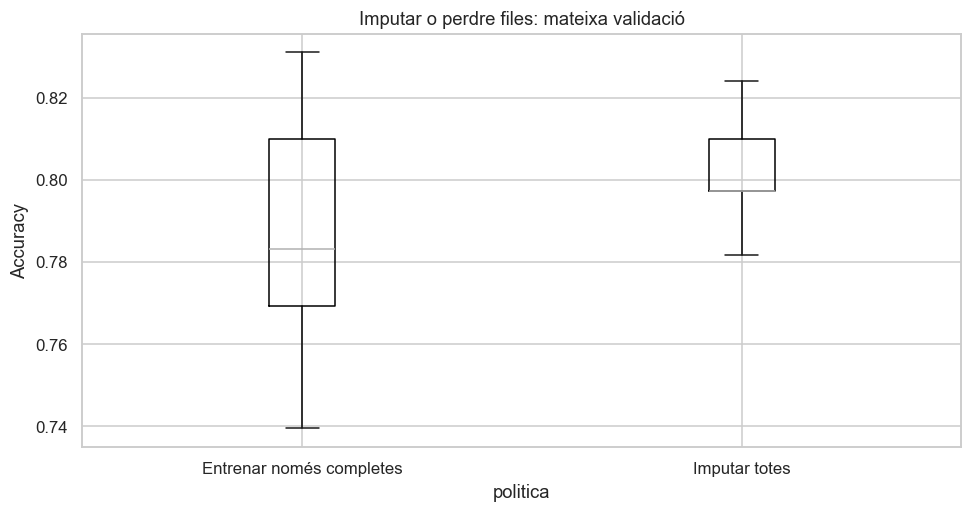

Eliminar files té dos costos: menys exemples per aprendre i una mostra que pot deixar fora sistemàticament passatgers amb informació incompleta. Per això mantindrem la imputació com a política general, encara que una mètrica calculada només amb files completes pogués semblar millor.

In [9]:
print('Files completes, totes les columnes originals:', desenvolupament.dropna().shape[0])
print('Files completes, només variables base:', X[numeriques + categories].dropna().shape[0])
files_eliminacio = []
for numero, (index_train, index_val) in enumerate(folds, start=1):
    X_train = X.iloc[index_train]
    X_val = X.iloc[index_val]
    y_train = y.iloc[index_train]
    y_val = y.iloc[index_val]
    completa_train = X_train[numeriques + categories].notna().all(axis=1)
    completa_val = X_val[numeriques + categories].notna().all(axis=1)
    for politica in ['Imputar totes', 'Entrenar només completes']:
        model = fer_model(LogisticRegression(max_iter=2000))
        if politica == 'Imputar totes':
            model.fit(X_train, y_train)
            n_train = len(X_train)
        else:
            model.fit(X_train.loc[completa_train], y_train.loc[completa_train])
            n_train = int(completa_train.sum())
        pred = model.predict(X_val)
        files_eliminacio.append({'fold': numero, 'politica': politica, 'n_train': n_train,
                                 'accuracy_tota_val': accuracy_score(y_val, pred),
                                 'f1_tota_val': f1_score(y_val, pred),
                                 'accuracy_val_completa': accuracy_score(y_val.loc[completa_val], pred[completa_val]),
                                 'cobertura_val_completa': completa_val.mean()})
eliminacio = pd.DataFrame(files_eliminacio)
display(eliminacio.groupby('politica').mean(numeric_only=True).drop(columns='fold'))
eliminacio.to_csv(sortida / 'eliminacio_files.csv', index=False)
eliminacio.boxplot(column='accuracy_tota_val', by='politica')
plt.suptitle('')
plt.title('Imputar o perdre files: mateixa validació')
plt.ylabel('Accuracy')
guardar_grafic('07_eliminar_o_imputar')
comentar('Eliminar files té dos costos: menys exemples per aprendre i una mostra '
         'que pot deixar fora sistemàticament passatgers amb informació incompleta. '
         'Per això mantindrem la imputació com a política general, encara que una '
         'mètrica calculada només amb files completes pogués semblar millor.')

### 2.2. Comprovació directa de la imputació d'edat

Seguim P1: amaguem el 20% d'edats conegudes i intentem reconstruir-les.
Repetim deu vegades amb les mateixes màscares per a cada mètode. Els valors
amagats no intervenen en la mitjana, mediana ni escalat. Per KNNImputer
escalem primer, perquè Fare no domini les distàncies.
És una simulació de nuls aleatoris en edats conegudes, no una demostració
que s'imputin bé les edats realment desconegudes.

,mean,std
metode,,
knn,10.701,0.4331
mean,11.504,0.5872
median,11.449,0.6481


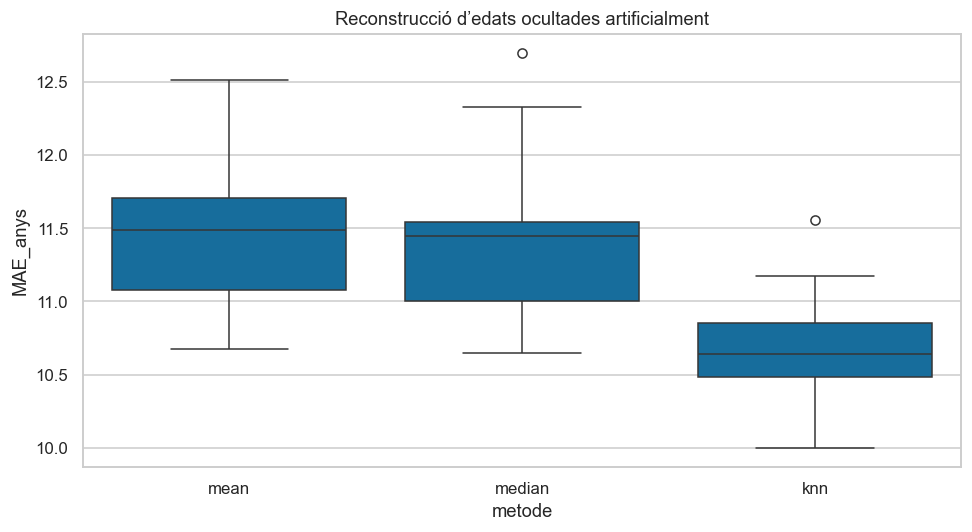

El MAE mitjà més baix correspon a **knn**. Això avalua reconstrucció d’edat, no supervivència. La prova següent avalua directament classificació; els dos criteris poden donar ordres diferents.

In [10]:
resultats_imputacio = []
columnes_imputar = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass']
for llavor in range(10):
    rng = np.random.default_rng(llavor)
    conegudes = X.index[X['Age'].notna()]
    amagades = rng.choice(conegudes, size=int(len(conegudes) * 0.2), replace=False)
    visibles = X[columnes_imputar].copy()
    visibles.loc[amagades, 'Age'] = np.nan
    for metode in ['mean', 'median', 'knn']:
        if metode == 'knn':
            escalador = StandardScaler()
            escalades = escalador.fit_transform(visibles)
            reomplertes = KNNImputer(n_neighbors=5).fit_transform(escalades)
            reconstruides = escalador.inverse_transform(reomplertes)
            edats = pd.Series(reconstruides[:, 0], index=X.index)
        else:
            imputador = SimpleImputer(strategy=metode)
            reconstruides = imputador.fit_transform(visibles)
            edats = pd.Series(reconstruides[:, 0], index=X.index)
        error = mean_absolute_error(X.loc[amagades, 'Age'], edats.loc[amagades])
        resultats_imputacio.append({'llavor': llavor, 'metode': metode, 'MAE_anys': error})
imputacions = pd.DataFrame(resultats_imputacio)
display(imputacions.groupby('metode')['MAE_anys'].agg(['mean', 'std']))
sns.boxplot(data=imputacions, x='metode', y='MAE_anys')
plt.title('Reconstrucció d’edats ocultades artificialment')
guardar_grafic('08_imputacio_edat')
imputacions.to_csv(sortida / 'imputacio_edat.csv', index=False)
millor_imputacio = imputacions.groupby('metode')['MAE_anys'].mean().idxmin()
comentar(f"El MAE mitjà més baix correspon a **{millor_imputacio}**. "
         'Això avalua reconstrucció d’edat, no supervivència. La prova següent '
         'avalua directament classificació; els dos criteris poden donar ordres diferents.')

### 2.3. Escalat, codificació i noves variables: una cosa cada vegada

Per comprovar S02, mantenim KNN amb k=5 i canviem només l'escala.
Amb logística comparem mitjana/mediana, imputació KNN, ordinal/one-hot,
log de tarifa i informació derivada. L'ordinal de Sex/Embarked es prova
com a contrast: els números inventen distàncies sense significat.
Afegim PCA (95% de variància), selecció del 50% de columnes i polinomis de grau 2.
PCA conserva variància de X, no necessàriament informació útil sobre y.
PolynomialFeatures permet interaccions a una logística, però augmenta dimensió
i risc de sobreajust. Totes aquestes transformacions s'ajusten dins dels folds.
Les proves exploratòries no utilitzen el test ni defineixen per si soles el guanyador final.

,experiment,train_accuracy,cv_accuracy,std_accuracy,cv_f1
0,KNN: escala cap,0.8062,0.7177,0.0198,0.6056
1,KNN: escala estandard,0.8546,0.7978,0.0207,0.7190
2,KNN: escala minmax,0.8532,0.7978,0.0210,0.7169
3,KNN: escala robust,0.8560,0.7935,0.0129,0.7224
4,Logística: median,0.8044,0.8020,0.0158,0.7301
5,Logística: mean,0.8037,0.8006,0.0182,0.7288
6,Logística: imputació KNN,0.8062,0.7964,0.0276,0.7241
7,Logística: ordinal,0.8023,0.7978,0.0295,0.7274
8,Logística: log tarifa,0.7988,0.7907,0.0221,0.7174
9,Logística: cabina coneguda,0.8097,0.8034,0.0204,0.7368


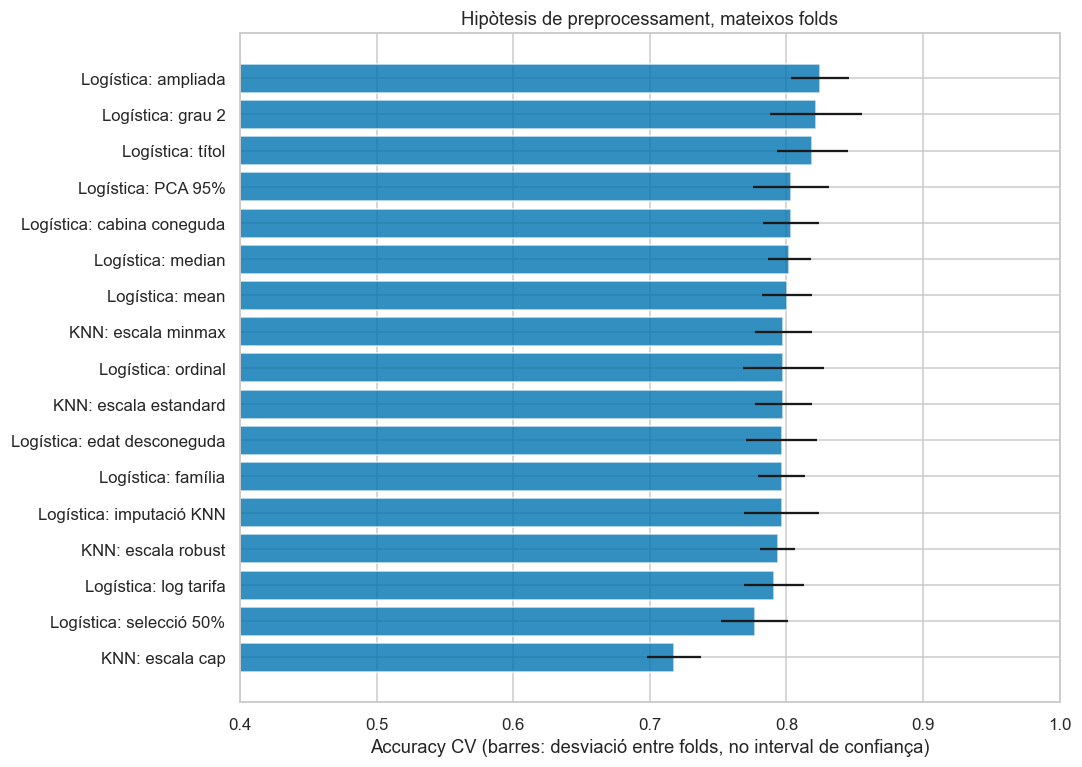

KNN passa de **0.718 sense escalar a 0.798 amb StandardScaler** (canvi de +8.01 punts percentuals). Això quantifica l’efecte de canviar la geometria. No deduïm que el mateix escalador sigui sempre el millor per a tots els models.

En aquesta prova exploratòria destaca **Logística: ampliada** amb accuracy 0.824. Les diferències s’han de llegir amb la variabilitat entre folds. Mantindrem dues representacions senzilles, base i ampliada, en la cerca principal, per comprovar també si l’efecte de les noves variables depèn del classificador.

In [11]:
experiments = []
for escala in ['cap', 'estandard', 'minmax', 'robust']:
    model = fer_model(KNeighborsClassifier(), escala=escala)
    experiments.append(avaluar_cv('KNN: escala ' + escala, model))
for metode in ['median', 'mean']:
    model = fer_model(LogisticRegression(max_iter=2000), imputacio=metode)
    experiments.append(avaluar_cv('Logística: ' + metode, model))

pre_knn = preparar(numeriques, categories)
pre_knn.set_params(num=Pipeline([('escalar', StandardScaler()), ('imputar', KNNImputer(n_neighbors=5))]))
model = Pipeline([('preparar', pre_knn), ('model', LogisticRegression(max_iter=2000))])
experiments.append(avaluar_cv('Logística: imputació KNN', model))
model = fer_model(LogisticRegression(max_iter=2000), encoding='ordinal')
experiments.append(avaluar_cv('Logística: ordinal', model))
model = fer_model(LogisticRegression(max_iter=2000),
                  num=['Age', 'LogTarifa', 'SibSp', 'Parch'])
experiments.append(avaluar_cv('Logística: log tarifa', model))
for nom, num, cat in [
    ('cabina coneguda', numeriques + ['CabinaConeguda'], categories),
    ('edat desconeguda', numeriques + ['EdatDesconeguda'], categories),
    ('títol', numeriques, cat_ampliades),
    ('família', numeriques + ['MidaFamilia', 'Sol'], categories),
    ('ampliada', num_ampliades, cat_ampliades)]:
    model = fer_model(LogisticRegression(max_iter=2000), num, cat)
    experiments.append(avaluar_cv('Logística: ' + nom, model))

for nom, transformacio in [('PCA 95%', PCA(n_components=0.95)),
                           ('selecció 50%', SelectPercentile(f_classif, percentile=50)),
                           ('grau 2', PolynomialFeatures(degree=2, include_bias=False))]:
    model = Pipeline([('preparar', preparar(numeriques, categories)),
                      ('transformar', transformacio),
                      ('model', LogisticRegression(C=1, max_iter=3000))])
    experiments.append(avaluar_cv('Logística: ' + nom, model))
preprocessament = pd.DataFrame(experiments)
display(preprocessament[['experiment', 'train_accuracy', 'cv_accuracy', 'std_accuracy', 'cv_f1']])
preprocessament.to_csv(sortida / 'preprocessament.csv', index=False)
comparar_grafic(preprocessament, '09_preprocessament', 'Hipòtesis de preprocessament, mateixos folds')
acc_sense = preprocessament.set_index('experiment').loc['KNN: escala cap', 'cv_accuracy']
acc_amb = preprocessament.set_index('experiment').loc['KNN: escala estandard', 'cv_accuracy']
comentar(f"KNN passa de **{acc_sense:.3f} sense escalar a {acc_amb:.3f} amb StandardScaler** "
         f"(canvi de {100*(acc_amb-acc_sense):+.2f} punts percentuals). "
         'Això quantifica l’efecte de canviar la geometria. No deduïm que el mateix '
         'escalador sigui sempre el millor per a tots els models.')
ordre_pre = preprocessament.sort_values('cv_accuracy', ascending=False)
comentar(f"En aquesta prova exploratòria destaca **{ordre_pre.iloc[0]['experiment']}** "
         f"amb accuracy {ordre_pre.iloc[0]['cv_accuracy']:.3f}. Les diferències s’han "
         'de llegir amb la variabilitat entre folds. Mantindrem dues representacions '
         'senzilles, base i ampliada, en la cerca principal, per comprovar també '
         'si l’efecte de les noves variables depèn del classificador.')

## 3. Models i validació creuada

Comparem cinc famílies, a més del DummyClassifier:

- **KNN:** voten els k veïns. Pocs veïns poden seguir soroll; molts poden suavitzar massa.
- **Logística:** suma ponderada i sigmoide; una frontera lineal en les variables transformades.
- **SVM:** busca un marge de separació. C alt penalitza més les violacions;
  RBF amb gamma alt fa una similitud molt local. Lineal i RBF són la mateixa família.
- **Arbre:** divideix les dades amb preguntes successives. És fàcil d'entendre,
  però un arbre sense límits pot memoritzar. Ens serveix per veure interaccions.
- **Random Forest:** combina molts arbres entrenats amb mostres bootstrap i
  subconjunts de variables. Redueix la variància d'un sol arbre, amb més cost
  i menys interpretació directa. El provem perquè les relacions no semblen totes lineals.

Primer fem servir els hiperparàmetres per defecte. Només fixem random_state,
max_iter de logística per assegurar convergència i n_jobs per controlar recursos.
Tots comparteixen folds i representació base. Els arbres van sense escalat.

,experiment,train_accuracy,cv_accuracy,std_accuracy,cv_f1,segons
3,SVM,0.8455,0.8174,0.0239,0.7447,1.4148
2,Logística,0.8044,0.8020,0.0158,0.7301,0.6805
1,KNN,0.8546,0.7978,0.0207,0.7190,0.7464
5,Random Forest,0.9824,0.7964,0.0243,0.7273,3.4356
4,Arbre,0.9824,0.7711,0.0176,0.6985,0.7353
0,Dummy,0.6166,0.6166,0.0031,0.0000,0.5935


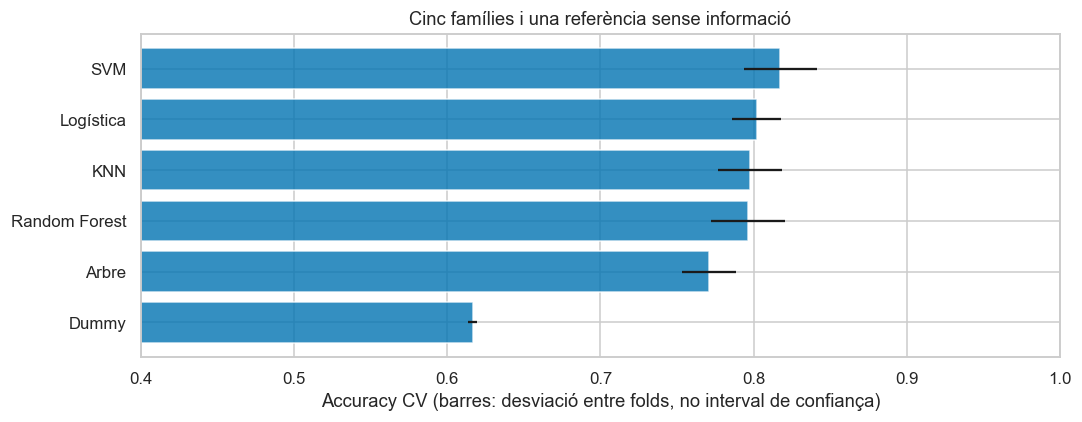

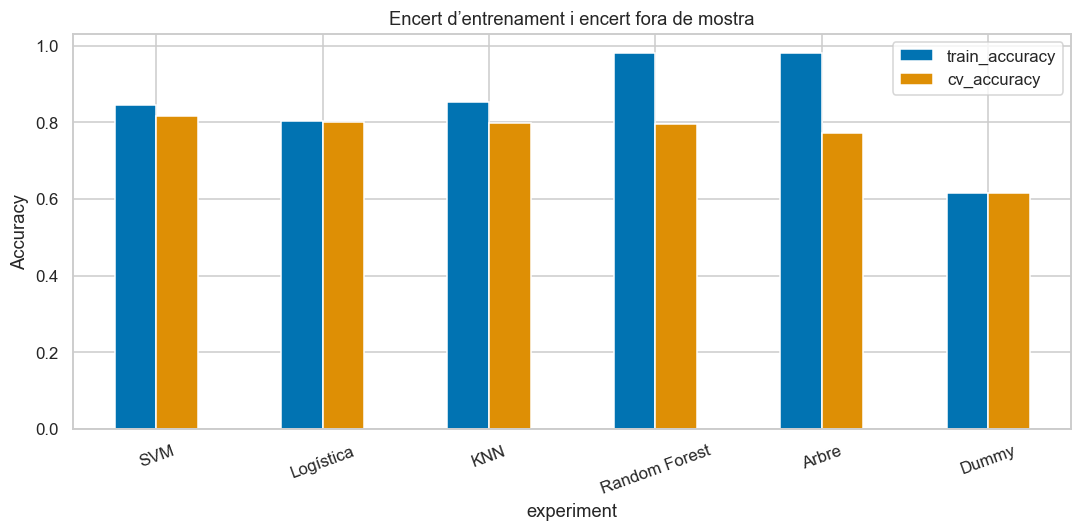

Amb valors per defecte guanya **SVM** per accuracy (0.817). Un train molt superior a CV és un símptoma de sobreajust, especialment en arbres sense límit. No descartem una família només per aquest primer resultat: encara podem regularitzar-la. Dummy sí que queda com a referència, no com a candidat útil per detectar supervivents.

In [12]:
classificadors = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'KNN': KNeighborsClassifier(),
    'Logística': LogisticRegression(max_iter=2000),
    'SVM': SVC(),
    'Arbre': DecisionTreeClassifier(random_state=LLAVOR),
    'Random Forest': RandomForestClassifier(random_state=LLAVOR, n_jobs=1)}
models_base = {}
files_base = []
for nom, classificador in classificadors.items():
    escala = 'estandard'
    if nom in ['Arbre', 'Random Forest', 'Dummy']:
        escala = 'cap'
    model = fer_model(classificador, escala=escala)
    models_base[nom] = model
    files_base.append(avaluar_cv(nom, model))
base = pd.DataFrame(files_base).sort_values('cv_accuracy', ascending=False)
display(base[['experiment', 'train_accuracy', 'cv_accuracy', 'std_accuracy', 'cv_f1', 'segons']])
base.to_csv(sortida / 'models_per_defecte.csv', index=False)
comparar_grafic(base, '10_models_base', 'Cinc famílies i una referència sense informació')
base.set_index('experiment')[['train_accuracy', 'cv_accuracy']].plot.bar(rot=20, figsize=(10, 5))
plt.ylabel('Accuracy')
plt.title('Encert d’entrenament i encert fora de mostra')
guardar_grafic('11_train_validacio')
comentar(f"Amb valors per defecte guanya **{base.iloc[0]['experiment']}** per accuracy "
         f"({base.iloc[0]['cv_accuracy']:.3f}). Un train molt superior a CV és un "
         'símptoma de sobreajust, especialment en arbres sense límit. No descartem '
         'una família només per aquest primer resultat: encara podem regularitzar-la. '
         'Dummy sí que queda com a referència, no com a candidat útil per detectar supervivents.')

### 3.1. Implementem el bucle K-fold a mà

En cada volta, quatre parts entrenen i la cinquena valida. Clonem el pipeline
perquè cap estat après passi d'un fold a l'altre. Cada passatger es valida
exactament una vegada. Estratifiquem per mantenir una proporció similar de classes.
La columna `test_score` de scikit-learn vol dir **validació del fold**, no el
test final reservat. Ho distingim a totes les taules.

In [13]:
files_manuals = []
visites = np.zeros(len(X), dtype=int)
for numero, (index_train, index_val) in enumerate(folds, start=1):
    model = clone(models_base['Logística'])
    model.fit(X.iloc[index_train], y.iloc[index_train])
    pred_train = model.predict(X.iloc[index_train])
    pred_val = model.predict(X.iloc[index_val])
    visites[index_val] += 1
    files_manuals.append({'fold': numero, 'n_train': len(index_train), 'n_val': len(index_val),
                         'proporcio_positius_val': y.iloc[index_val].mean(),
                         'train_accuracy': accuracy_score(y.iloc[index_train], pred_train),
                         'val_accuracy': accuracy_score(y.iloc[index_val], pred_val)})
manual = pd.DataFrame(files_manuals)
display(manual)
assert (visites == 1).all()
acc_sklearn = base.set_index('experiment').loc['Logística', 'cv_accuracy']
assert np.isclose(manual['val_accuracy'].mean(), acc_sklearn)
print('La mitjana manual coincideix amb cross_validate:', manual['val_accuracy'].mean())

,fold,n_train,n_val,proporcio_positius_val,train_accuracy,val_accuracy
0,1,569,143,0.3846,0.8049,0.7972
1,2,569,143,0.3846,0.8014,0.7972
2,3,570,142,0.3873,0.8053,0.8099
3,4,570,142,0.3803,0.8140,0.7817
4,5,570,142,0.3803,0.7965,0.8239


La mitjana manual coincideix amb cross_validate: 0.8019797104304146


### 3.2. Què passa si canviem folds o llavor?

Provem 3, 5 i 10 folds, amb quatre llavors. No escollim la partició que dona
millor nota: és una prova d'estabilitat amb logística fixada. Més folds vol
dir més ajustos i un entrenament més gran en cada ajust; no garanteix una
estimació millor en una mostra concreta. Les puntuacions dels folds no són
independents, perquè els conjunts d'entrenament se solapen.

,folds,llavor,cv_accuracy,std_accuracy,cv_f1,segons
0,3,0,0.8019,0.0239,0.7331,0.4511
1,3,7,0.7950,0.0144,0.7234,0.4265
2,3,42,0.7908,0.0299,0.7222,0.4375
3,3,123,0.7950,0.0213,0.7217,0.4453
4,5,0,0.7963,0.0398,0.7279,0.6097
5,5,7,0.7977,0.0436,0.7265,0.6418
6,5,42,0.8020,0.0158,0.7301,0.7030
7,5,123,0.7908,0.0177,0.7181,0.6657
8,10,0,0.7962,0.0536,0.7279,1.0955
9,10,7,0.8034,0.0552,0.7316,1.1224


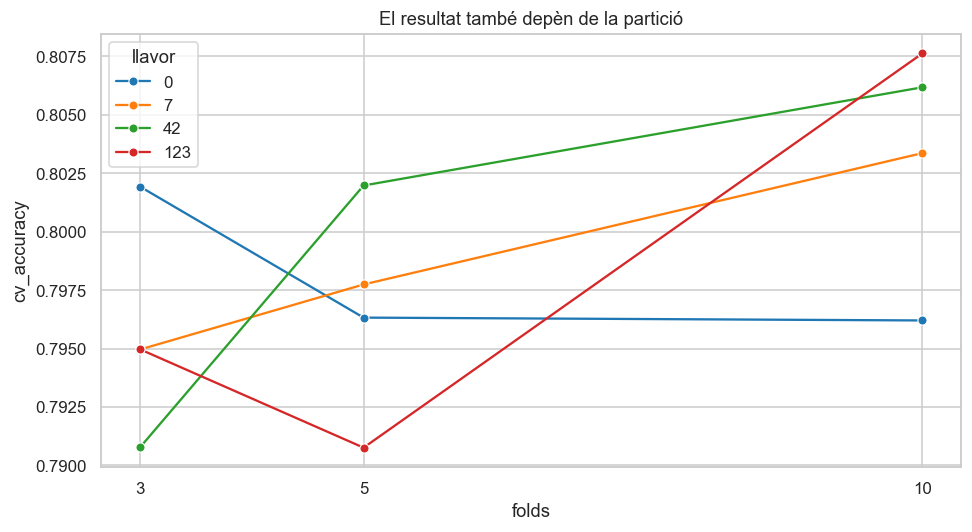

En aquesta logística, les mitjanes d’accuracy van de 0.791 a 0.808. Aquesta variació ajuda a posar en perspectiva millores molt petites. Mantenim els cinc folds inicials per no escollir la llavor amb el millor resultat.

In [14]:
files_estabilitat = []
for nombre_folds in [3, 5, 10]:
    for llavor in [0, 7, 42, 123]:
        cv = StratifiedKFold(n_splits=nombre_folds, shuffle=True, random_state=llavor)
        fila = avaluar_cv('Logística', models_base['Logística'], cv)
        fila['folds'] = nombre_folds
        fila['llavor'] = llavor
        files_estabilitat.append(fila)
estabilitat = pd.DataFrame(files_estabilitat)
display(estabilitat[['folds', 'llavor', 'cv_accuracy', 'std_accuracy', 'cv_f1', 'segons']])
sns.lineplot(data=estabilitat, x='folds', y='cv_accuracy', hue='llavor', marker='o', palette='tab10')
plt.xticks([3, 5, 10])
plt.title('El resultat també depèn de la partició')
guardar_grafic('12_folds_llavors')
estabilitat.to_csv(sortida / 'estabilitat.csv', index=False)
comentar(f"En aquesta logística, les mitjanes d’accuracy van de "
         f"{estabilitat['cv_accuracy'].min():.3f} a {estabilitat['cv_accuracy'].max():.3f}. "
         'Aquesta variació ajuda a posar en perspectiva millores molt petites. '
         'Mantenim els cinc folds inicials per no escollir la llavor amb el millor resultat.')

### 3.3. Cerca d'hiperparàmetres

Fem GridSearchCV: provem totes les combinacions de la graella. Incloem la
representació base i ampliada. L'imputació és mediana i l'encoding one-hot.
Provem C de 0.1 a 10, k entre 3 i 21, pesos de classe, profunditat i mida
mínima de fulla. Són graelles petites i comprensibles, no una garantia d'òptim global.

Es calculen totes les mètriques en els mateixos ajustos. En aquest apartat
ordenem per accuracy; a l'apartat 4 reconsiderarem el resultat segons F1.
Guardem **totes** les configuracions, no només la guanyadora. Els temps són
els d'aquesta màquina i no una comparació de maquinari universal.

In [15]:
graelles = {
    'KNN': {'model__n_neighbors': [3, 5, 9, 15, 21],
            'model__weights': ['uniform', 'distance'], 'model__p': [1, 2]},
    'Logística': {'model__C': [0.1, 1, 10], 'model__class_weight': [None, 'balanced']},
    'SVM': [
        {'model__kernel': ['linear'], 'model__C': [0.1, 1, 10],
         'model__class_weight': [None, 'balanced']},
        {'model__kernel': ['rbf'], 'model__C': [0.1, 1, 10],
         'model__gamma': ['scale', 0.01, 0.1], 'model__class_weight': [None, 'balanced']}],
    'Arbre': {'model__max_depth': [3, 5, 8, None],
              'model__min_samples_leaf': [1, 5, 10], 'model__class_weight': [None, 'balanced']},
    'Random Forest': {'model__n_estimators': [100], 'model__max_depth': [5, 10, None],
                     'model__min_samples_leaf': [1, 3, 6], 'model__max_features': ['sqrt', 0.8]}}
cerques = {}
resultats_graella = []
for nom in graelles:
    inici = perf_counter()
    escala = 'estandard'
    if nom in ['Arbre', 'Random Forest']:
        escala = 'cap'
    graella = graelles[nom]
    if isinstance(graella, dict):
        graella = [graella]
    graella_completa = []
    for part in graella:
        nova_part = part.copy()
        nova_part['preparar'] = [preparar(numeriques, categories, escala),
                                 preparar(num_ampliades, cat_ampliades, escala)]
        graella_completa.append(nova_part)
    cerca = GridSearchCV(models_base[nom], graella_completa, cv=folds,
                         scoring=metriques_cv, refit='accuracy', n_jobs=TREBALLADORS,
                         return_train_score=True, error_score='raise')
    cerca.fit(X, y)
    cerques[nom] = cerca
    taula = pd.DataFrame(cerca.cv_results_)
    taula['familia'] = nom
    representacions = []
    parametres_llegibles = []
    for parametres in taula['params']:
        pre = parametres['preparar']
        if len(pre.transformers[0][2]) == len(numeriques):
            representacions.append('base')
        else:
            representacions.append('ampliada')
        text_params = {}
        for clau, valor in parametres.items():
            if clau != 'preparar':
                text_params[clau.replace('model__', '')] = valor
        parametres_llegibles.append(str(text_params))
    taula['representacio'] = representacions
    taula['parametres'] = parametres_llegibles
    taula['segons_cerca'] = perf_counter() - inici
    resultats_graella.append(taula)
    print(nom, ':', len(taula), 'configuracions;', round(perf_counter() - inici, 1), 'segons')

graella_total = pd.concat(resultats_graella, ignore_index=True)
columnes_guardar = ['familia', 'representacio', 'parametres', 'mean_fit_time', 'segons_cerca']
for metrica in metriques_cv:
    columnes_guardar += ['mean_train_' + metrica, 'mean_test_' + metrica, 'std_test_' + metrica]
graella_total[columnes_guardar].to_csv(sortida / 'totes_les_configuracions.csv', index=False)
millors_accuracy = graella_total.sort_values('mean_test_accuracy', ascending=False).groupby('familia', sort=False).head(1)
display(millors_accuracy[['familia', 'representacio', 'parametres', 'mean_train_accuracy',
                          'mean_test_accuracy', 'std_test_accuracy', 'mean_test_f1']])
print('Configuracions totals:', len(graella_total))
print('Ajustos de CV de la graella:', len(graella_total) * len(folds))

KNN : 40 configuracions; 36.3 segons


Logística : 12 configuracions; 8.0 segons


SVM : 48 configuracions; 52.4 segons


Arbre : 48 configuracions; 26.4 segons


Random Forest : 36 configuracions; 96.3 segons


,familia,representacio,parametres,mean_train_accuracy,mean_test_accuracy,std_test_accuracy,mean_test_f1
181,Random Forest,ampliada,"{'max_depth': None, 'max_features': 0.8, 'min_...",0.9143,0.8315,0.0252,0.7711
91,SVM,ampliada,"{'C': 10, 'class_weight': None, 'gamma': 0.01,...",0.8350,0.8315,0.0261,0.7691
45,Logística,ampliada,"{'C': 1, 'class_weight': None}",0.8325,0.8245,0.0192,0.7693
101,Arbre,ampliada,"{'class_weight': None, 'max_depth': 3, 'min_sa...",0.8325,0.8245,0.0402,0.7649
29,KNN,ampliada,"{'n_neighbors': 15, 'p': 2, 'weights': 'uniform'}",0.8304,0.8230,0.0168,0.7539


Configuracions totals: 184
Ajustos de CV de la graella: 920


### 3.4. Veure per què canvia el resultat

Els gràfics següents fixen els altres paràmetres: no barregen arbitràriament
C, pesos i representacions. En KNN busquem la relació entre k i generalització;
en l'arbre, la distància entre train i validació; en SVM, la interacció C/gamma.
El punt amb més accuracy de train no té per què ser el que convé.

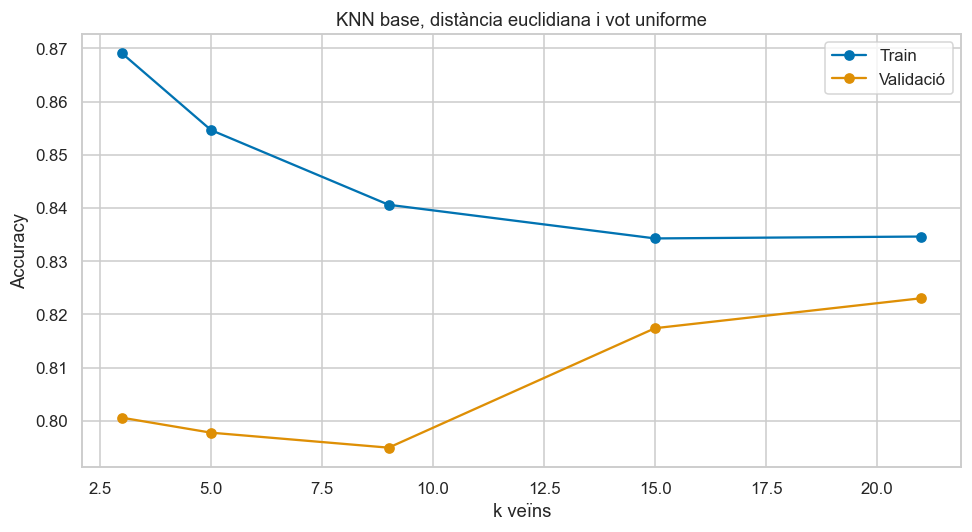

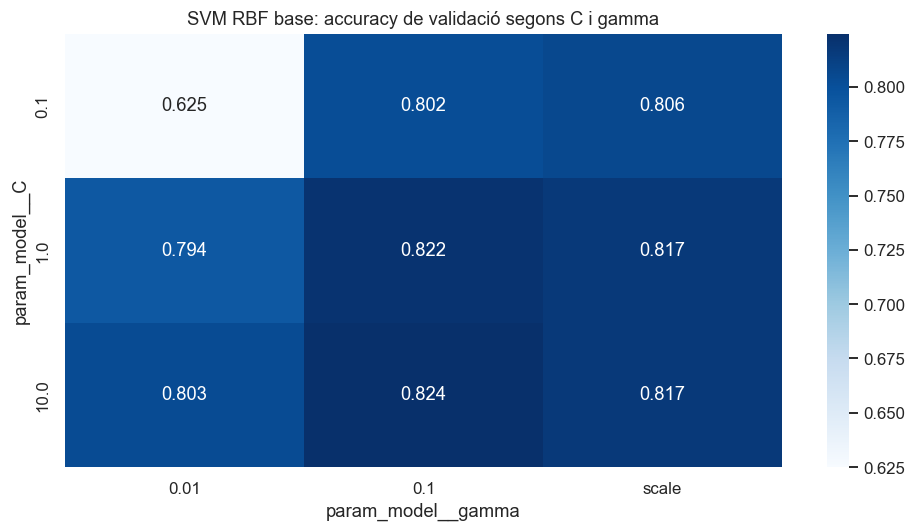

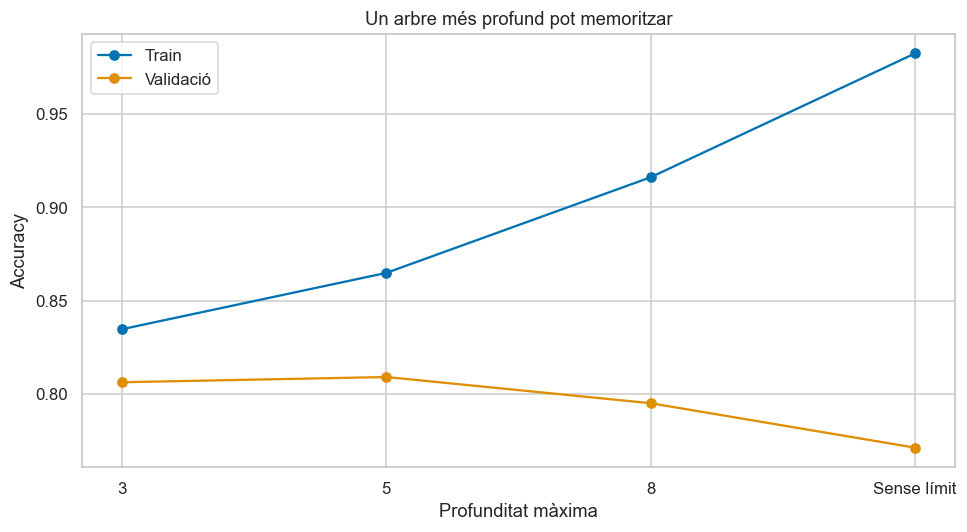

In [16]:
knn = pd.DataFrame(cerques['KNN'].cv_results_)
knn = knn[(knn['param_model__weights'] == 'uniform') & (knn['param_model__p'] == 2)].copy()
# La primera representació de cada configuració és la base; la identifiquem per columnes.
es_base = []
for pre in knn['param_preparar']:
    es_base.append(len(pre.transformers[0][2]) == 4)
knn = knn.loc[es_base].sort_values('param_model__n_neighbors')
plt.plot(knn['param_model__n_neighbors'].astype(int), knn['mean_train_accuracy'], 'o-', label='Train')
plt.plot(knn['param_model__n_neighbors'].astype(int), knn['mean_test_accuracy'], 'o-', label='Validació')
plt.xlabel('k veïns')
plt.ylabel('Accuracy')
plt.title('KNN base, distància euclidiana i vot uniforme')
plt.legend()
guardar_grafic('13_knn_k')

svm = pd.DataFrame(cerques['SVM'].cv_results_)
svm = svm[(svm['param_model__kernel'] == 'rbf') & svm['param_model__class_weight'].isna()].copy()
es_base = []
for pre in svm['param_preparar']:
    es_base.append(len(pre.transformers[0][2]) == 4)
svm = svm.loc[es_base]
sns.heatmap(svm.pivot(index='param_model__C', columns='param_model__gamma', values='mean_test_accuracy'),
            annot=True, fmt='.3f', cmap='Blues')
plt.title('SVM RBF base: accuracy de validació segons C i gamma')
guardar_grafic('14_svm_c_gamma')

arbre = pd.DataFrame(cerques['Arbre'].cv_results_)
arbre = arbre[(arbre['param_model__min_samples_leaf'] == 1) & arbre['param_model__class_weight'].isna()].copy()
es_base = []
for pre in arbre['param_preparar']:
    es_base.append(len(pre.transformers[0][2]) == 4)
arbre = arbre.loc[es_base]
etiquetes = arbre['param_model__max_depth'].fillna('Sense límit').astype(str)
plt.plot(etiquetes, arbre['mean_train_accuracy'], 'o-', label='Train')
plt.plot(etiquetes, arbre['mean_test_accuracy'], 'o-', label='Validació')
plt.xlabel('Profunditat màxima')
plt.ylabel('Accuracy')
plt.title('Un arbre més profund pot memoritzar')
plt.legend()
guardar_grafic('15_profunditat_arbre')

### 3.5. Grid Search o Random Search?

Fem una prova petita i transparent: RandomizedSearchCV avalua 12 de les
configuracions SVM de la mateixa graella. Mesurem temps i resultat.
**No és una comparació amb igual pressupost temporal** ni hem executat la
prova opcional d'una hora. Grid és exhaustiu dins d'aquesta graella; random
pot explorar espais més grans amb menys combinacions. Amb una hora i moltes
dimensions, començaria amb random i després afinaria prop de bones zones.
La cerca bayesiana usa resultats anteriors per proposar candidats; successive
halving reparteix recursos i elimina candidats. No els hem implementat aquí.

In [17]:
inici = perf_counter()
cerca_aleatoria = RandomizedSearchCV(
    models_base['SVM'], cerques['SVM'].param_grid, n_iter=12,
    scoring='accuracy', cv=folds, random_state=LLAVOR, n_jobs=TREBALLADORS,
    return_train_score=True, error_score='raise')
cerca_aleatoria.fit(X, y)
temps_random = perf_counter() - inici
comparacio_cerca = pd.DataFrame([
    {'metode': 'Grid SVM', 'candidats': len(cerques['SVM'].cv_results_['params']),
     'accuracy_cv': cerques['SVM'].best_score_,
     'segons': graella_total.loc[graella_total['familia'] == 'SVM', 'segons_cerca'].iloc[0]},
    {'metode': 'Random SVM', 'candidats': 12,
     'accuracy_cv': cerca_aleatoria.best_score_, 'segons': temps_random}])
display(comparacio_cerca)
comparacio_cerca.to_csv(sortida / 'metodes_cerca.csv', index=False)
comentar('La cerca aleatòria és una prova de pressupost reduït; no l’afegim '
         'com una sisena família. Els seus candidats ja formen part de la graella '
         'exhaustiva, així que no amplia l’espai de solucions de la selecció final.')

,metode,candidats,accuracy_cv,segons
0,Grid SVM,48,0.8315,52.4146
1,Random SVM,12,0.8259,6.6513


La cerca aleatòria és una prova de pressupost reduït; no l’afegim com una sisena família. Els seus candidats ja formen part de la graella exhaustiva, així que no amplia l’espai de solucions de la selecció final.

## 4. Quina mètrica ens interessa i què amaga l'accuracy?

Considerem positiu `Survived=1`. Un FP és predir supervivència per a algú que
no va sobreviure; un FN és no detectar un supervivent real. Aquí reconstruïm
dades històriques: no hi ha un cost operatiu definit ni una política de rescat.

- Accuracy: (TP + TN) / N. Tots els encerts pesen igual.
- Precision: TP / (TP + FP). De les supervivències predites, quantes són certes?
- Recall: TP / (TP + FN). Quants supervivents reals detectem?
- F1: 2PR / (P + R). Equilibra les dues anteriors, però ignora TN.
- ROC: recall contra FP / (FP + TN), per a tots els llindars.
- PR: precision contra recall. Fa més visible el rendiment de la classe positiva.
- Average precision (AP): resumeix precision ponderant increments de recall.
  No és exactament l'àrea trapezoidal sota la corba PR.

Priorizem F1 pel criteri indicat al principi; accuracy continua sent útil
perquè el desequilibri no és extrem. ROC-AUC avalua ordenació, no encert amb
un llindar ni calibratge. La referència PR és la prevalença; en ROC és la
diagonal. Donem més protagonisme a PR per analitzar supervivents, sense amagar ROC.
`classification_report` mostra precision, recall, F1 i suport de cada classe,
a més de mitjanes macro i ponderades; el suport és el nombre de casos reals.

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
0,0.802,0.7826,0.764,0.6996,0.7304,0.8526,0.8314


              precision    recall  f1-score   support

 No sobreviu       0.82      0.87      0.84       439
    Sobreviu       0.76      0.70      0.73       273

    accuracy                           0.80       712
   macro avg       0.79      0.78      0.79       712
weighted avg       0.80      0.80      0.80       712



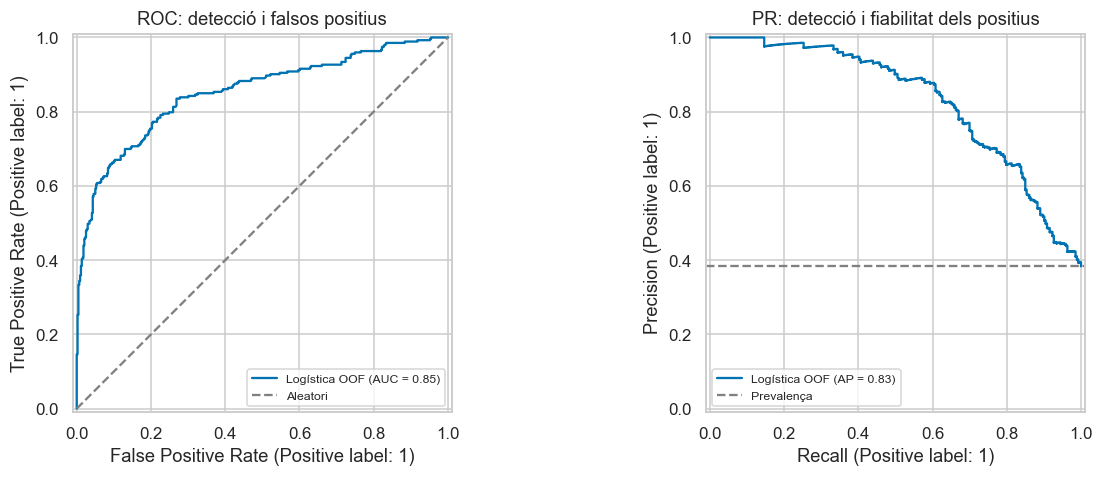

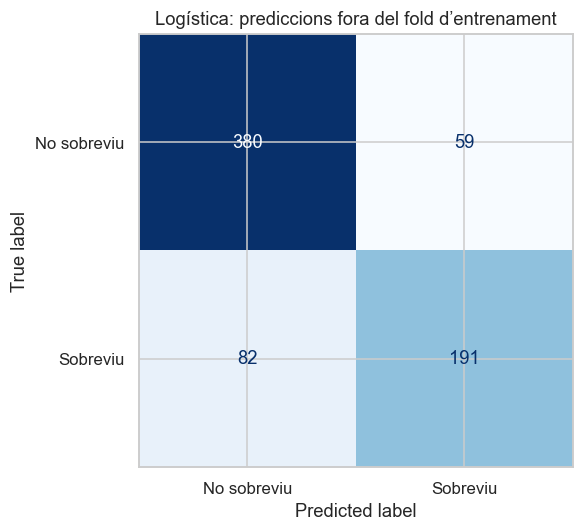

In [18]:
def resum_metriques(real, predit, puntuacions):
    return {'accuracy': accuracy_score(real, predit),
            'balanced_accuracy': balanced_accuracy_score(real, predit),
            'precision': precision_score(real, predit, zero_division=0),
            'recall': recall_score(real, predit, zero_division=0),
            'f1': f1_score(real, predit, zero_division=0),
            'roc_auc': roc_auc_score(real, puntuacions),
            'average_precision': average_precision_score(real, puntuacions)}

def mostrar_corbes(real, puntuacions, titol, nom_fitxer):
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
    RocCurveDisplay.from_predictions(real, puntuacions, ax=eixos[0], name=titol)
    eixos[0].plot([0, 1], [0, 1], '--', color='grey', label='Aleatori')
    eixos[0].set_title('ROC: detecció i falsos positius')
    eixos[0].legend(fontsize=8)
    PrecisionRecallDisplay.from_predictions(real, puntuacions, ax=eixos[1], name=titol)
    eixos[1].axhline(np.mean(real), linestyle='--', color='grey', label='Prevalença')
    eixos[1].set_title('PR: detecció i fiabilitat dels positius')
    eixos[1].legend(fontsize=8)
    guardar_grafic(nom_fitxer)

def mostrar_confusio(real, predit, titol, nom_fitxer):
    ConfusionMatrixDisplay.from_predictions(real, predit,
        display_labels=['No sobreviu', 'Sobreviu'], cmap='Blues', colorbar=False)
    plt.title(titol)
    guardar_grafic(nom_fitxer)

# La logística d'aquesta demostració té paràmetres fixos, no triats amb y.
prob_logistica = cross_val_predict(models_base['Logística'], X, y, cv=folds,
                                   method='predict_proba', n_jobs=TREBALLADORS)[:, 1]
pred_logistica = (prob_logistica >= 0.5).astype(int)
display(pd.DataFrame([resum_metriques(y, pred_logistica, prob_logistica)]))
print(classification_report(y, pred_logistica, target_names=['No sobreviu', 'Sobreviu'], zero_division=0))
mostrar_corbes(y, prob_logistica, 'Logística OOF', '16_logistica_roc_pr')
mostrar_confusio(y, pred_logistica, 'Logística: prediccions fora del fold d’entrenament', '17_logistica_confusio')

### 4.1. El llindar canvia els errors, no l'ordenació

Les probabilitats anteriors són out-of-fold (OOF): cada fila es prediu amb un
model que no l'ha entrenada. Mantenim aquests scores i variem el llindar.
Baixar-lo tendeix a augmentar recall i falsos positius; precision no ha de
canviar monòtonament en una mostra finita. L'F1 màxim d'aquesta taula seria
optimista si l'uséssim alhora per seleccionar i avaluar el llindar. Per això
aquesta prova és explicativa i mantenim la política final per defecte.

,llindar,precision,recall,f1,accuracy,FP,FN
0,0.10,0.4542,0.9267,0.6096,0.5449,304,20
1,0.15,0.5465,0.8828,0.6751,0.6742,200,32
2,0.20,0.5810,0.8535,0.6914,0.7079,168,40
3,0.25,0.6301,0.8425,0.7210,0.7500,135,43
4,0.30,0.6577,0.8022,0.7228,0.7640,114,54
5,0.35,0.6918,0.7729,0.7301,0.7809,94,62
6,0.40,0.7034,0.7473,0.7247,0.7823,86,69
7,0.45,0.7164,0.7216,0.7190,0.7837,78,76
8,0.50,0.7640,0.6996,0.7304,0.8020,59,82
9,0.55,0.7854,0.6703,0.7233,0.8034,50,90


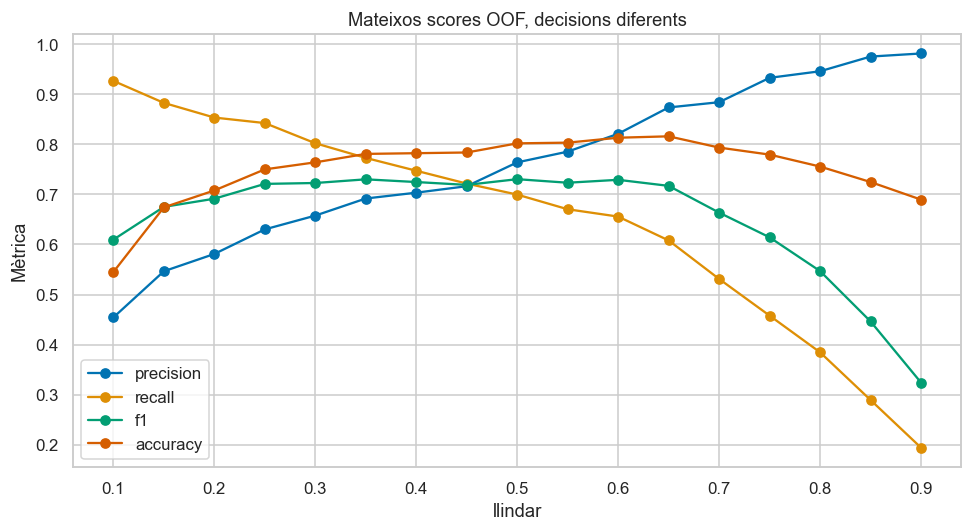

In [19]:
files_llindar = []
for llindar in np.arange(0.10, 0.91, 0.05):
    pred = (prob_logistica >= llindar).astype(int)
    fila = resum_metriques(y, pred, prob_logistica)
    fila['llindar'] = llindar
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    fila.update({'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
    files_llindar.append(fila)
llindars = pd.DataFrame(files_llindar)
display(llindars[['llindar', 'precision', 'recall', 'f1', 'accuracy', 'FP', 'FN']])
llindars.plot(x='llindar', y=['precision', 'recall', 'f1', 'accuracy'], marker='o')
plt.title('Mateixos scores OOF, decisions diferents')
plt.ylabel('Mètrica')
guardar_grafic('18_llindars')
llindars.to_csv(sortida / 'llindars_logistica.csv', index=False)

### 4.2. Es manté el millor model quan prioritzem F1?

Tornem a ordenar **tots els candidats** per F1, no només els que havien
guanyat amb accuracy. Si només canviéssim l'etiqueta de la mètrica del millor
model anterior, no estaríem fent una selecció coherent.

Les puntuacions d'aquesta cerca són de selecció i poden ser optimistes per
haver provat moltes opcions. No les presentem com una avaluació independent.
El test reservat donarà l'avaluació final, després de tancar les decisions.

,familia,representacio,parametres,mean_train_f1,mean_test_f1,std_test_f1,mean_test_accuracy,mean_test_auc,mean_test_ap
181,Random Forest,ampliada,"{'max_depth': None, 'max_features': 0.8, 'min_...",0.8828,0.7711,0.0253,0.8315,0.8848,0.8562
83,SVM,ampliada,"{'C': 1, 'class_weight': 'balanced', 'gamma': ...",0.7996,0.7709,0.0329,0.8161,0.8592,0.8308
45,Logística,ampliada,"{'C': 1, 'class_weight': None}",0.7778,0.7693,0.0203,0.8245,0.8724,0.8511
101,Arbre,ampliada,"{'class_weight': None, 'max_depth': 3, 'min_sa...",0.7730,0.7649,0.0478,0.8245,0.8624,0.7943
29,KNN,ampliada,"{'n_neighbors': 15, 'p': 2, 'weights': 'uniform'}",0.7658,0.7539,0.0222,0.8230,0.8600,0.8135


,familia,mean_test_accuracy_triat_accuracy,mean_test_f1_triat_accuracy,mean_test_accuracy_triat_f1,mean_test_f1_triat_f1
0,Random Forest,0.8315,0.7711,0.8315,0.7711
1,SVM,0.8315,0.7691,0.8161,0.7709
2,Logística,0.8245,0.7693,0.8245,0.7693
3,Arbre,0.8245,0.7649,0.8245,0.7649
4,KNN,0.8230,0.7539,0.8230,0.7539


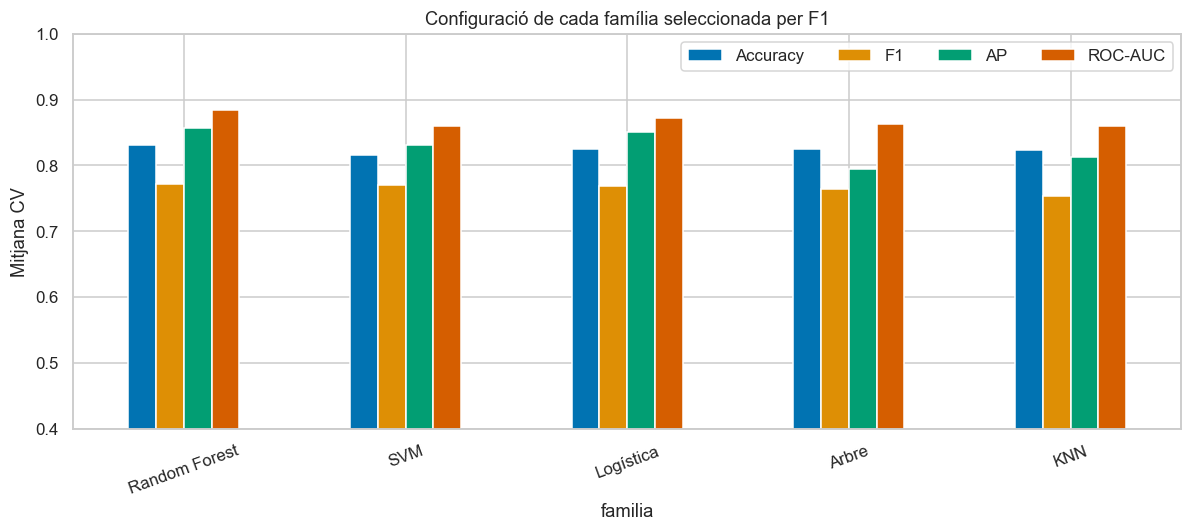

Per accuracy guanya **Random Forest** amb 0.831. Per F1 escollim **Random Forest**, representació **ampliada**, amb F1 CV **0.771** i accuracy CV 0.831. La configuració queda fixada ara: `{'max_depth': None, 'max_features': 0.8, 'min_samples_leaf': 3, 'n_estimators': 100}`. El test no ha intervingut en aquesta decisió.

In [20]:
millors_f1 = graella_total.sort_values('mean_test_f1', ascending=False).groupby('familia', sort=False).head(1)
display(millors_f1[['familia', 'representacio', 'parametres', 'mean_train_f1',
                    'mean_test_f1', 'std_test_f1', 'mean_test_accuracy', 'mean_test_auc', 'mean_test_ap']])
comparacio_metrica = millors_accuracy[['familia', 'mean_test_accuracy', 'mean_test_f1']].merge(
    millors_f1[['familia', 'mean_test_accuracy', 'mean_test_f1']], on='familia',
    suffixes=('_triat_accuracy', '_triat_f1'))
display(comparacio_metrica)
comparacio_metrica.to_csv(sortida / 'accuracy_contra_f1.csv', index=False)
millors_f1.set_index('familia')[['mean_test_accuracy', 'mean_test_f1', 'mean_test_ap', 'mean_test_auc']].plot.bar(
    rot=20, figsize=(11, 5))
plt.ylim(0.4, 1)
plt.ylabel('Mitjana CV')
plt.title('Configuració de cada família seleccionada per F1')
plt.legend(['Accuracy', 'F1', 'AP', 'ROC-AUC'], ncol=4)
guardar_grafic('19_comparacio_metriques')

guanyador_accuracy = millors_accuracy.iloc[0]
guanyador_f1 = millors_f1.iloc[0]
nom_final = guanyador_f1['familia']
cerca_final = cerques[nom_final]
index_final = int(np.argmax(cerca_final.cv_results_['mean_test_f1']))
parametres_final = cerca_final.cv_results_['params'][index_final]
model_final = clone(cerca_final.estimator).set_params(**parametres_final)
comentar(f"Per accuracy guanya **{guanyador_accuracy['familia']}** amb "
         f"{guanyador_accuracy['mean_test_accuracy']:.3f}. Per F1 escollim **{nom_final}**, "
         f"representació **{guanyador_f1['representacio']}**, amb F1 CV "
         f"**{guanyador_f1['mean_test_f1']:.3f}** i accuracy CV "
         f"{guanyador_f1['mean_test_accuracy']:.3f}. La configuració queda fixada ara: "
         f"`{guanyador_f1['parametres']}`. El test no ha intervingut en aquesta decisió.")

### 4.3. Aprèn més si li donem més dades?

Una corba d'aprenentatge compara train i validació amb diferents mides.
La fem sobre desenvolupament amb la configuració ja escollida. És un
diagnòstic de selecció, no una nova avaluació independent. Si train es manté
alt i validació queda més baixa, encara hi ha variància o informació que falta.

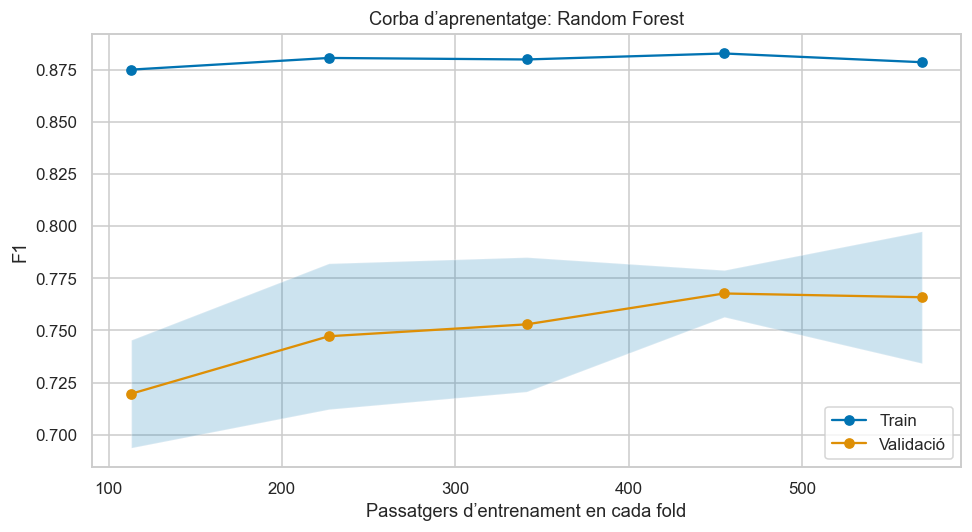

,n_train,f1_train,f1_validacio
0,113,0.8750,0.7196
1,227,0.8806,0.7472
2,341,0.8799,0.7529
3,455,0.8827,0.7677
4,569,0.8786,0.7659


In [21]:
mides, puntuacions_train, puntuacions_val = learning_curve(
    model_final, X, y, cv=folds, scoring='f1', train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    shuffle=True, random_state=LLAVOR, n_jobs=TREBALLADORS)
plt.plot(mides, puntuacions_train.mean(axis=1), 'o-', label='Train')
plt.plot(mides, puntuacions_val.mean(axis=1), 'o-', label='Validació')
plt.fill_between(mides, puntuacions_val.mean(axis=1) - puntuacions_val.std(axis=1),
                 puntuacions_val.mean(axis=1) + puntuacions_val.std(axis=1), alpha=0.2)
plt.xlabel('Passatgers d’entrenament en cada fold')
plt.ylabel('F1')
plt.title('Corba d’aprenentatge: ' + nom_final)
plt.legend()
guardar_grafic('20_corba_aprenentatge')
display(pd.DataFrame({'n_train': mides, 'f1_train': puntuacions_train.mean(axis=1),
                      'f1_validacio': puntuacions_val.mean(axis=1)}))

### 4.4. El problema dels passatgers que comparteixen bitllet

Una partició per passatger pot posar companys de viatge en train i validació.
Provem StratifiedGroupKFold agrupant per Ticket. És una pregunta més exigent:
com funciona el model en bitllets no vistos? Ticket és un indicador imperfecte
de família; no detecta tots els vincles. El test principal continua mesurant
passatgers aleatoris del mateix fitxer, no famílies completament noves.
No canviem de model després d'aquesta prova: és un diagnòstic de sensibilitat.

,experiment,cv_accuracy,std_accuracy,cv_f1,std_f1
0,Passatgers aleatoris,0.8315,0.0282,0.7711,0.0282
1,Bitllets separats,0.8199,0.0528,0.7471,0.0832


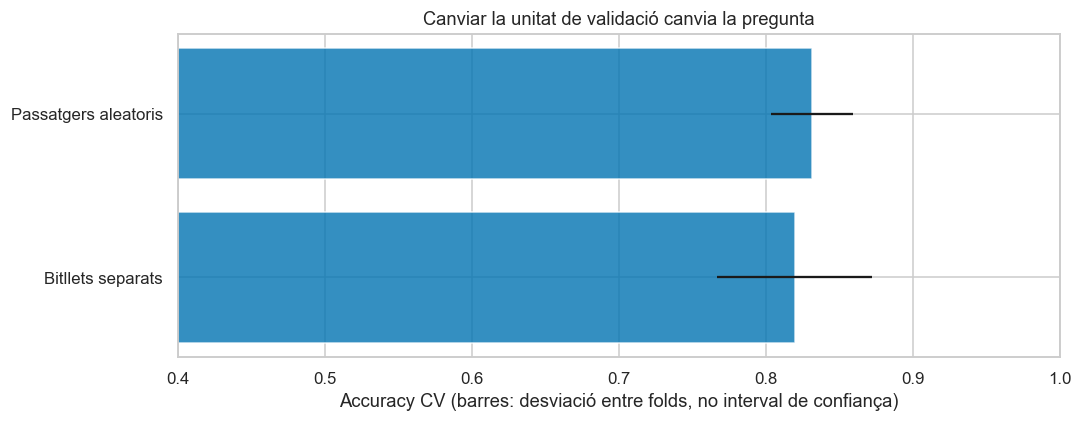

F1 per passatgers: 0.771; per bitllets separats: 0.747. A més dels grups canvien els folds, de manera que la diferència no aïlla una única causa. La configuració havia estat triada amb CV per passatgers: la prova de grups no és una estimació de tot el procés de selecció per grups.

In [22]:
grups = desenvolupament['Ticket'].astype(str)
cv_grups = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=LLAVOR)
folds_grups = list(cv_grups.split(X, y, groups=grups))
for index_train, index_val in folds_grups:
    assert set(grups.iloc[index_train]).isdisjoint(set(grups.iloc[index_val]))
sensibilitat = pd.DataFrame([
    avaluar_cv('Passatgers aleatoris', model_final),
    avaluar_cv('Bitllets separats', model_final, folds_grups)])
display(sensibilitat[['experiment', 'cv_accuracy', 'std_accuracy', 'cv_f1', 'std_f1']])
sensibilitat.to_csv(sortida / 'validacio_per_bitllet.csv', index=False)
comparar_grafic(sensibilitat, '21_grups_bitllet', 'Canviar la unitat de validació canvia la pregunta')
comentar(f"F1 per passatgers: {sensibilitat.iloc[0]['cv_f1']:.3f}; "
         f"per bitllets separats: {sensibilitat.iloc[1]['cv_f1']:.3f}. "
         'A més dels grups canvien els folds, de manera que la diferència no aïlla '
         'una única causa. La configuració havia estat triada amb CV per passatgers: '
         'la prova de grups no és una estimació de tot el procés de selecció per grups.')

## 5. Test final: obrim les dades reservades

Model, variables, hiperparàmetres, mètrica i política de decisió ja estan fixats.
Entrenem amb tot desenvolupament i prediem el test una vegada. A partir
d'aquestes mateixes prediccions fem el report, corbes i auditoria d'errors.
No tornem a ajustar el model per millorar aquests números.
Si guanya SVM, fem servir decision_function per a ROC/PR: és un score,
no una probabilitat. La classificació es fa amb `predict`, llindar intern 0.
Per als altres models el llindar habitual de probabilitat és 0.5 (amb les
convencions pròpies d'empat de cada implementació).

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
Random Forest | test reservat,0.8101,0.7914,0.7778,0.7101,0.7424,0.8432,0.8181


              precision    recall  f1-score   support

 No sobreviu       0.83      0.87      0.85       110
    Sobreviu       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



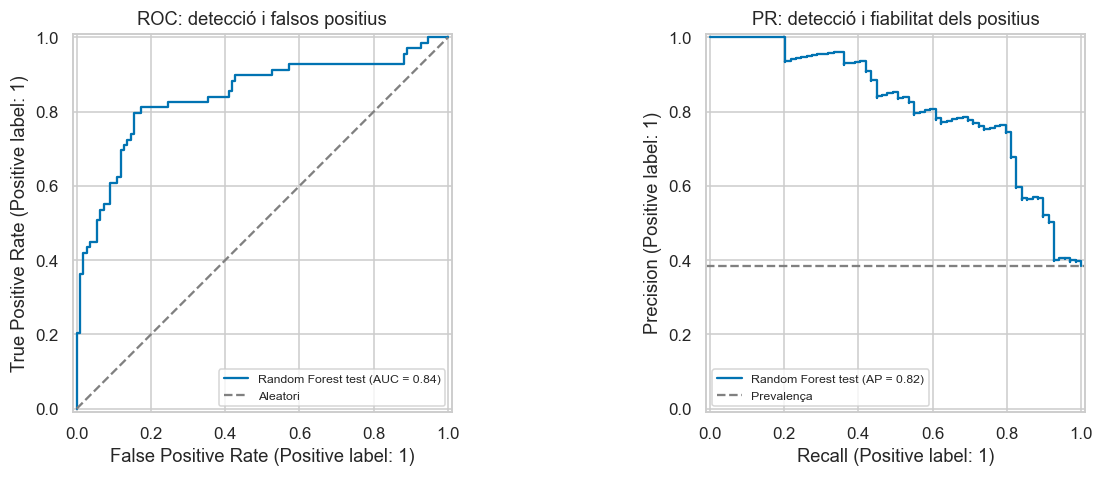

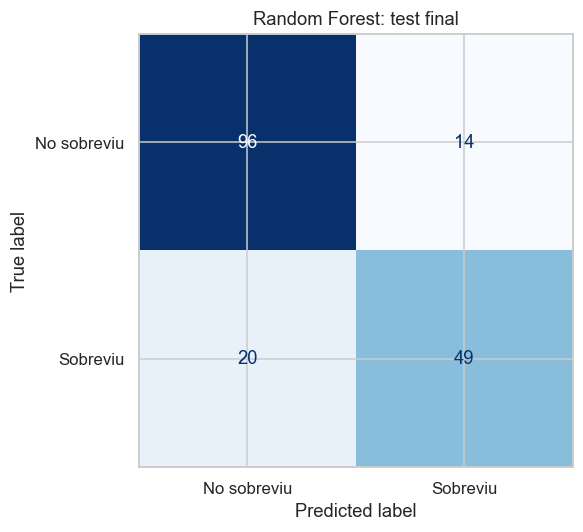

Al test de **179 passatgers**, el model encerta **145 casos (81.0%)**. Detecta **49 de 69 supervivents** (recall 71.0%); de les 63 supervivències predites, 49 són correctes (precision 77.8%). Hi ha **14 falsos positius i 20 falsos negatius**. F1 és 0.742, ROC-AUC 0.843 i AP 0.818, davant una prevalença de 0.385.

La corba ROC mostra fins a quin punt ordenem supervivents per damunt de no supervivents. La corba PR mostra el compromís quan volem recuperar més supervivents: cal llegir si la precision baixa massa. Una àrea alta no implica haver encertat totes les persones ni tenir probabilitats calibrades.

In [23]:
X_test = crear_variables(test_reservat.drop(columns='Survived'))
y_test = test_reservat['Survived'].copy()
model_final.fit(X, y)
pred_test = model_final.predict(X_test)
if hasattr(model_final, 'predict_proba'):
    score_test = model_final.predict_proba(X_test)[:, 1]
    tipus_score = 'probabilitat estimada, no calibrada explícitament'
else:
    score_test = model_final.decision_function(X_test)
    tipus_score = 'decision_function, no probabilitat'
final = resum_metriques(y_test, pred_test, score_test)
display(pd.DataFrame([final], index=[nom_final + ' | test reservat']))
print(classification_report(y_test, pred_test, target_names=['No sobreviu', 'Sobreviu'], zero_division=0))
mostrar_corbes(y_test, score_test, nom_final + ' test', '22_final_roc_pr')
mostrar_confusio(y_test, pred_test, nom_final + ': test final', '23_final_confusio')
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
comentar(f"Al test de **{len(y_test)} passatgers**, el model encerta "
         f"**{int((pred_test == y_test).sum())} casos ({final['accuracy']:.1%})**. "
         f"Detecta **{tp} de {tp+fn} supervivents** (recall {final['recall']:.1%}); "
         f"de les {tp+fp} supervivències predites, {tp} són correctes "
         f"(precision {final['precision']:.1%}). Hi ha **{fp} falsos positius i {fn} falsos negatius**. "
         f"F1 és {final['f1']:.3f}, ROC-AUC {final['roc_auc']:.3f} i AP "
         f"{final['average_precision']:.3f}, davant una prevalença de {y_test.mean():.3f}.")
comentar('La corba ROC mostra fins a quin punt ordenem supervivents per damunt '
         'de no supervivents. La corba PR mostra el compromís quan volem recuperar '
         'més supervivents: cal llegir si la precision baixa massa. Una àrea alta '
         'no implica haver encertat totes les persones ni tenir probabilitats calibrades.')

### 5.1. Incertesa: no tractem 179 persones com si fossin tota la població

Fem 1.000 remostrejos bootstrap de parelles (etiqueta, predicció) del test,
mantenint el model fix. Els percentils 2.5 i 97.5 donen intervals orientatius.
No inclouen la incertesa de tornar a entrenar ni de triar models. A més,
el bootstrap per passatger assumeix independència, limitada pels companys
de bitllet. No són garanties per a altres vaixells o poblacions.

,resultat,percentil_2_5,percentil_97_5
accuracy,0.8101,0.7542,0.8659
balanced_accuracy,0.7914,0.7262,0.8531
precision,0.7778,0.6666,0.8727
recall,0.7101,0.5901,0.8154
f1,0.7424,0.6428,0.8176
roc_auc,0.8432,0.7696,0.9038
average_precision,0.8181,0.7236,0.8893


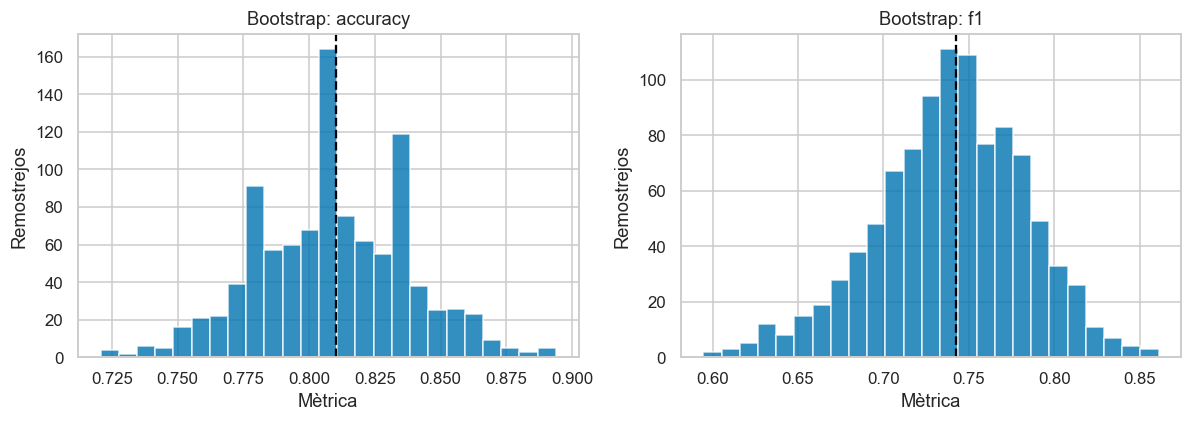

In [24]:
rng = np.random.default_rng(2026)
files_bootstrap = []
real = y_test.to_numpy()
for repeticio in range(1000):
    indexs = rng.integers(0, len(real), size=len(real))
    if len(np.unique(real[indexs])) == 2:
        files_bootstrap.append(resum_metriques(real[indexs], pred_test[indexs], score_test[indexs]))
bootstrap = pd.DataFrame(files_bootstrap)
intervals = pd.DataFrame({'resultat': pd.Series(final),
                          'percentil_2_5': bootstrap.quantile(0.025),
                          'percentil_97_5': bootstrap.quantile(0.975)})
display(intervals)
intervals.to_csv(sortida / 'intervals_test.csv')
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica in zip(eixos, ['accuracy', 'f1']):
    ax.hist(bootstrap[metrica], bins=25, alpha=0.8)
    ax.axvline(final[metrica], color='black', linestyle='--')
    ax.set(title='Bootstrap: ' + metrica, xlabel='Mètrica', ylabel='Remostrejos')
guardar_grafic('24_incertesa_bootstrap')

### 5.2. On ens equivoquem? Sexe, classe, edat coneguda i infants

La mitjana global pot amagar diferències. Mostrem N, positius reals, TP,
FP, FN, TN i mètriques. Si un grup no té positius, el recall és indefinit:
el mostrem com NaN, no com un zero interpretat com mal rendiment.
Aquesta auditoria no s'utilitza per reajustar el model. Els grups petits
tenen molta incertesa; comparar-los no estableix causes ni una prova de justícia.

,variable,grup,n,positius,TP,FP,FN,TN,recall,precision,accuracy
0,Sex,female,61,45,41,5,4,11,0.9111,0.8913,0.8525
1,Sex,male,118,24,8,9,16,85,0.3333,0.4706,0.7881
2,Pclass,1,45,25,19,9,6,11,0.7600,0.6786,0.6667
3,Pclass,2,34,20,18,1,2,13,0.9000,0.9474,0.9118
4,Pclass,3,100,24,12,4,12,72,0.5000,0.7500,0.8400
5,EdatConeguda,No,40,12,8,3,4,25,0.6667,0.7273,0.8250
6,EdatConeguda,Sí,139,57,41,11,16,71,0.7193,0.7885,0.8058
7,GrupEdat,Adult (16 o més),122,47,33,10,14,65,0.7021,0.7674,0.8033
8,GrupEdat,Desconeguda,40,12,8,3,4,25,0.6667,0.7273,0.8250
9,GrupEdat,Infant (<16),17,10,8,1,2,6,0.8000,0.8889,0.8235


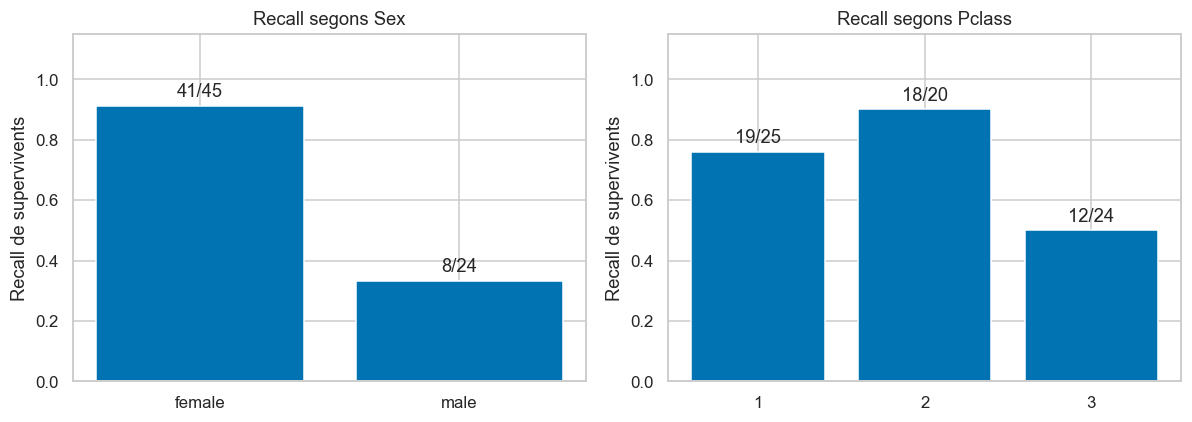

,PassengerId,Sex,Pclass,Age,Cabin,Survived,predit,score,error,EdatConeguda,GrupEdat
553,554,male,3,22.0,NaN,1,0,0.1532,True,Sí,Adult (16 o més)
559,560,female,3,36.0,NaN,1,0,0.3647,True,Sí,Adult (16 o més)
536,537,male,1,45.0,B38,0,1,0.6858,True,Sí,Adult (16 o més)
698,699,male,1,49.0,C68,0,1,0.5149,True,Sí,Adult (16 o més)
216,217,female,3,27.0,NaN,1,0,0.3978,True,Sí,Adult (16 o més)
712,713,male,1,48.0,C126,1,0,0.4228,True,Sí,Adult (16 o més)
455,456,male,3,29.0,NaN,1,0,0.1269,True,Sí,Adult (16 o més)
489,490,male,3,9.0,NaN,1,0,0.4585,True,Sí,Infant (<16)
165,166,male,3,9.0,NaN,1,0,0.4119,True,Sí,Infant (<16)
745,746,male,1,70.0,B22,0,1,0.7203,True,Sí,Adult (16 o més)


Els exemples d’error permeten veure casos concrets, però no explicar per què aquella persona va sobreviure. No tenim posició exacta, accés als bots ni totes les circumstàncies del naufragi. El model només resumeix patrons de les variables disponibles.

In [25]:
prediccions = test_reservat[['PassengerId', 'Sex', 'Pclass', 'Age', 'Cabin', 'Survived']].copy()
prediccions['predit'] = pred_test
prediccions['score'] = score_test
prediccions['error'] = prediccions['predit'] != prediccions['Survived']
prediccions['EdatConeguda'] = np.where(prediccions['Age'].notna(), 'Sí', 'No')
prediccions['GrupEdat'] = 'Adult (16 o més)'
prediccions.loc[prediccions['Age'] < 16, 'GrupEdat'] = 'Infant (<16)'
prediccions.loc[prediccions['Age'].isna(), 'GrupEdat'] = 'Desconeguda'
files_grups = []
for columna in ['Sex', 'Pclass', 'EdatConeguda', 'GrupEdat']:
    for valor, grup in prediccions.groupby(columna):
        tn_g, fp_g, fn_g, tp_g = confusion_matrix(grup['Survived'], grup['predit'], labels=[0, 1]).ravel()
        recall_g = np.nan
        precision_g = np.nan
        if tp_g + fn_g > 0:
            recall_g = tp_g / (tp_g + fn_g)
        if tp_g + fp_g > 0:
            precision_g = tp_g / (tp_g + fp_g)
        files_grups.append({'variable': columna, 'grup': str(valor), 'n': len(grup),
                            'positius': int(grup['Survived'].sum()), 'TP': tp_g, 'FP': fp_g,
                            'FN': fn_g, 'TN': tn_g, 'recall': recall_g, 'precision': precision_g,
                            'accuracy': accuracy_score(grup['Survived'], grup['predit'])})
subgrups = pd.DataFrame(files_grups)
display(subgrups)
subgrups.to_csv(sortida / 'errors_per_subgrup.csv', index=False)
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for columna, ax in zip(['Sex', 'Pclass'], eixos):
    part = subgrups[subgrups['variable'] == columna]
    ax.bar(part['grup'], part['recall'])
    ax.set(title='Recall segons ' + columna, ylim=(0, 1.15), ylabel='Recall de supervivents')
    for posicio, (_, fila) in enumerate(part.iterrows()):
        ax.text(posicio, fila['recall'] + 0.03,
                str(int(fila['TP'])) + '/' + str(int(fila['positius'])), ha='center')
guardar_grafic('25_errors_subgrups')
display(prediccions.loc[prediccions['error']].head(12))
comentar('Els exemples d’error permeten veure casos concrets, però no explicar '
         'per què aquella persona va sobreviure. No tenim posició exacta, accés '
         'als bots ni totes les circumstàncies del naufragi. El model només '
         'resumeix patrons de les variables disponibles.')

### 5.3. Quines variables utilitza el model?

Fem importància per permutació al test com a explicació **posterior**, no
com a selecció de variables. Barregem una columna original i observem la
caiguda de F1. Recalculem les variables derivades abans de cada predicció:
si barregem Sex però deixéssim una còpia derivada de Sex, la prova seria enganyosa.
Les variables correlacionades es poden substituir; una importància baixa
no vol dir que una variable sigui irrellevant. Les combinacions permutades
poden ser poc realistes, així que no són efectes causals.

,variable,caiguda_f1,std
7,Cabin,-0.0224,0.0134
4,Parch,0.0128,0.0117
5,Fare,0.0133,0.0220
3,SibSp,0.0329,0.0133
6,Embarked,0.0350,0.0127
2,Age,0.0566,0.0131
8,Name,0.0936,0.0283
1,Sex,0.1438,0.0254
0,Pclass,0.1454,0.0210


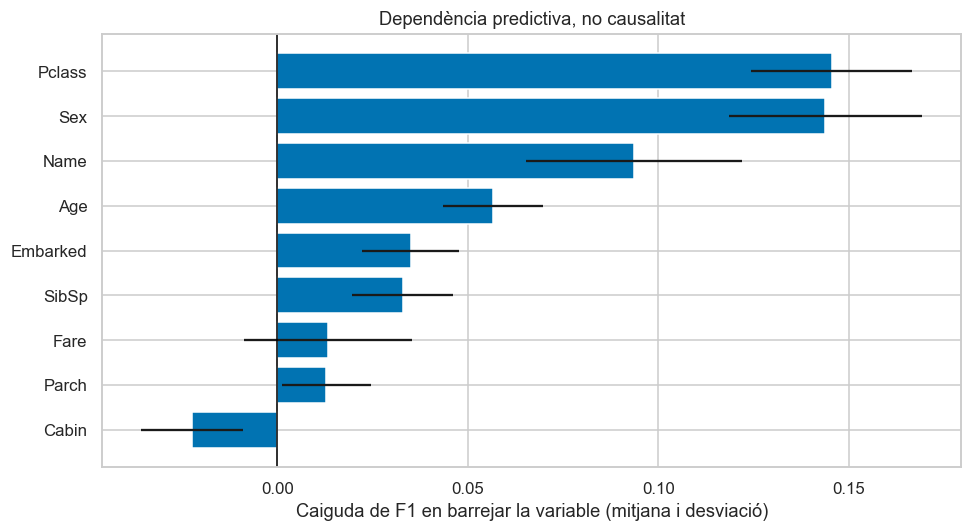

In [26]:
# Codi explícit per tornar a calcular totes les derivades en cada permutació.
files_importancia = []
rng = np.random.default_rng(42)
for columna in ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Cabin', 'Name']:
    caigudes = []
    for repeticio in range(10):
        barrejat = test_reservat.drop(columns='Survived').copy()
        barrejat[columna] = rng.permutation(barrejat[columna].to_numpy())
        pred_barrejat = model_final.predict(crear_variables(barrejat))
        caigudes.append(final['f1'] - f1_score(y_test, pred_barrejat))
    files_importancia.append({'variable': columna, 'caiguda_f1': np.mean(caigudes),
                              'std': np.std(caigudes, ddof=1)})
importancies = pd.DataFrame(files_importancia).sort_values('caiguda_f1')
display(importancies)
plt.barh(importancies['variable'], importancies['caiguda_f1'], xerr=importancies['std'])
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Caiguda de F1 en barrejar la variable (mitjana i desviació)')
plt.title('Dependència predictiva, no causalitat')
guardar_grafic('26_importancia_permutacio')
importancies.to_csv(sortida / 'importancies.csv', index=False)

### 5.4. Conclusió i límits

El resultat principal no és haver trobat un model perfecte. Hem passat d'un
CSV amb buits i categories a un protocol que es pot explicar i repetir.
Hem comprovat l'efecte d'escalar, eliminar files, imputar, afegir informació,
canviar complexitat, canviar folds i canviar la mètrica de selecció.

La cerca només cobreix les graelles declarades. Provar molts models amb els
mateixos folds fa optimistes els resultats de selecció; el test independent
redueix aquest problema, però té poques files i pot compartir bitllets amb
desenvolupament. La prova per grups ensenya per què importa definir què és un cas nou.

El títol, la classe i la cabina poden actuar com a indicadors de condicions
socials i de com es van registrar les dades. L'absència de cabina pot no
reproduir-se en un altre registre. No sabem si la mostra representa tota
la població del vaixell. No atribuïm els errors a defectes personals.

**Ús possible:** una demostració educativa o una eina per explorar patrons
d'aquest registre històric. **Condició de no ús:** no extrapolar a seguretat
marítima actual ni a decisions de rescat o valoració individual de persones.

**Millores que tindrien sentit:** validar per grups des del principi si la
pregunta són famílies noves; fer validació creuada niada de tota la selecció;
aconseguir més dades i millor documentació dels nuls; calibrar probabilitats
amb validació separada si s'han d'interpretar com risc; fixar costos FP/FN
abans d'optimitzar un llindar. No hem aplicat aquestes millores després de veure
el test, perquè llavors el test deixaria de ser independent.

In [27]:
resum = {'model': nom_final, 'representacio': guanyador_f1['representacio'],
         'parametres': guanyador_f1['parametres'], 'n_desenvolupament': len(X),
         'n_test': len(X_test), 'configuracions_graella': len(graella_total),
         'ajustos_graella': len(graella_total) * 5,
         'cv_f1_seleccio': float(guanyador_f1['mean_test_f1']),
         'cv_accuracy_seleccio': float(guanyador_f1['mean_test_accuracy']),
         'test': final, 'confusio': {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)},
         'tipus_score': tipus_score, 'sha256_dades': empremta, 'versions': versions}
(sortida / 'resum.json').write_text(json.dumps(resum, indent=2, ensure_ascii=False), encoding='utf-8')
prediccions.to_csv(sortida / 'prediccions_test.csv', index=False)
comentar(f"**Resposta final:** escollim {nom_final} amb variables {guanyador_f1['representacio']}. "
         f"El test dona accuracy **{final['accuracy']:.3f}** i F1 **{final['f1']:.3f}**. "
         f"Hem comparat **{len(graella_total)} configuracions** en la cerca principal "
         f"(**{len(graella_total)*5} ajustos de CV**), a més de les proves de preprocessament "
         'i estabilitat. La decisió es basa en F1 de desenvolupament; els errors i '
         'els intervals del test mostren el límit d’aquesta conclusió.')

**Resposta final:** escollim Random Forest amb variables ampliada. El test dona accuracy **0.810** i F1 **0.742**. Hem comparat **184 configuracions** en la cerca principal (**920 ajustos de CV**), a més de les proves de preprocessament i estabilitat. La decisió es basa en F1 de desenvolupament; els errors i els intervals del test mostren el límit d’aquesta conclusió.

## 6. Discussió dels resultats: què defensem i què no?

Aquesta lectura complementa les explicacions de cada experiment. Tots els números provenen de les taules de l'execució. Les decisions de selecció es prenen amb desenvolupament. Les observacions del test són diagnòstics posteriors i no han provocat canvis del model.

### 6.1. Les dades suggereixen interaccions, no una única regla

El creuament sexe/classe és més informatiu que mirar només una mitjana. A les figures veiem que les dones de primera i segona classe tenen taxes altes, mentre que les de tercera queden força per sota. Entre els homes també canvia la taxa segons la classe. Això dona sentit a provar models amb interaccions, però no permet reconstruir les circumstàncies de cada persona.

La matriu de correlació mostra una relació forta entre classe i cabina registrada. Per tant, dues columnes predictives poden estar recollint informació semblant. En el cas d'Age i EdatDesconeguda apareix una casella buida: quan Age té valor, l'indicador sempre és zero. No hi ha variació per calcular aquesta correlació per parelles. **El blanc és una correlació indefinida, no una correlació igual a zero.**

MidaFamilia tampoc compta tota la xarxa social: només suma els familiars recollits a SibSp i Parch, més el passatger. Ticket pot compartir-se entre persones, però no identifica totes les famílies. Fare és la tarifa registrada i no n'hem inventat un preu individual dividint-lo pel nombre de files del mateix bitllet, que pot estar incomplet.

### 6.2. Perdre files no és una solució neutra

Entrenar només amb files completes de les variables base deixa de mitjana 458.4 files per fold, davant 569.6 amb imputació. En la mateixa validació completa, les accuracies són 0.787 i 0.802, respectivament. El filtre de casos complets només cobreix el 80.5% de les files de validació. El seu resultat parcial respondria a una població diferent.

Preferim conservar passatgers i imputar. És una decisió que combina resultat, cobertura i mida de mostra. Si exigíssim també Cabin, perdríem moltes més files. No hem convertit una cabina desconeguda en una falsa cabina coneguda: n'hem conservat l'indicador.

### 6.3. Reconstruir millor una edat no garanteix classificar millor

En deu simulacions, el MAE mitjà és 10.70 anys amb KNNImputer, 11.45 amb mediana i 11.50 amb mitjana. KNN reconstrueix millor les edats ocultades en aquesta prova. Però la logística amb imputació KNN dona accuracy 0.796, davant 0.802 amb mediana.

No és una contradicció. El MAE penalitza la distància en anys, mentre que la classificació depèn de com aquests valors afecten una frontera conjunta amb altres atributs. A més, hem amagat edats conegudes de manera aleatòria; els nuls reals podrien seguir un altre patró. Per això no podem afirmar que hem descobert les edats reals ni que KNN sigui sempre millor.

### 6.4. La prova de geometria sí que té un efecte gran

Amb k=5 fixat, KNN sense escalar obté 0.718 d'accuracy; amb StandardScaler, 0.798. Són 8.01 punts percentuals de diferència. Les unitats de Fare estaven condicionant la noció de proximitat.

MinMax dona 0.798 i RobustScaler 0.794. Aquí la diferència important és escalar respecte a no escalar; no hi ha evidència suficient per proclamar un guanyador universal entre els escaladors. RobustScaler redueix la influència dels extrems en l'escala, però no elimina passatgers.

### 6.5. Més transformacions no sempre ajuden

La logística base amb mediana dona 0.802. Afegir només el títol puja a 0.819; la representació ampliada arriba a 0.824. El títol pot resumir edat, sexe i convencions socials. No l'interpretem com una causa de supervivència.

Afegir només família dona 0.796, i substituir tarifa per log de tarifa dona 0.791. Són exemples d'idees raonables que no milloren aquesta logística per si soles. El resultat de combinar-les pot ser diferent, i per això comparem representacions completes dins de la cerca.

PCA al 95% dona 0.803, molt a prop de la base. No necessitem comprimir una representació tan petita si no hi ha un benefici clar i perdrem interpretació. Seleccionar el 50% dona 0.777: una regla univariant pot perdre informació complementària. Grau 2 puja l'accuracy a 0.822, però l'F1 és 0.746 i la dispersió entre folds augmenta. No l'escollim només perquè train millori.

L'encoding ordinal de totes les categories dona 0.798, davant 0.802 amb one-hot. La diferència és petita; el motiu principal per mantenir one-hot és que Embarked no té un ordre numèric justificat.

### 6.6. Sobreajust i cerca: no confondre un màxim amb una victòria clara

L'arbre per defecte arriba a accuracy de train 0.982, però CV baixa a 0.771. Això fa visible el sobreajust. Limitar la profunditat i el nombre mínim de casos per fulla és una manera comprensible de controlar-lo. El Random Forest per defecte també té una separació gran entre train i CV: combinar arbres no elimina tots els problemes.

Amb la cerca, Random Forest i una SVM RBF empaten en accuracy CV arrodonida a sis decimals: 0.831498. Per F1, Random Forest dona 0.771066, la millor SVM 0.770871 i logística 0.769302. La diferència entre RF i SVM és de només 0.000195. **Escollim el màxim segons la regla fixada, però no afirmem una superioritat estadística clara del Random Forest.** Una logística més senzilla continuaria sent una alternativa defensable si la interpretació fos prioritària. No l'hem avaluat després al test per triar la que hi quedés millor.

Canviar de mètrica sí que canvia la configuració preferida de SVM: la millor per F1 utilitza pesos de classe equilibrats, mentre que la millor per accuracy no. Aquesta és la resposta pràctica a «la comparació amb accuracy aguanta?»: el primer model pot continuar destacant, però les configuracions i el compromís d'errors no són els mateixos.

La logística fixada dona mitjanes d'accuracy entre 0.791 i 0.808 quan variem folds i llavor. Aquesta prova no és un test estadístic de RF contra SVM, però recorda que les particions aporten variabilitat i que una quarta xifra decimal no és una garantia.

Grid SVM prova 48 candidats i dona 0.831, amb 52.4 segons. Random prova 12 candidats i dona 0.826, amb 6.7 segons. Aquesta comparació il·lustra un pressupost de candidats menor, no una prova amb temps igual ni una conclusió universal sobre els mètodes.

### 6.7. El test és menys bo que la selecció i això és part del resultat

L'F1 baixa de 0.771 en CV de selecció a 0.742 en el test. No hem intentat arreglar aquesta diferència buscant una altra llavor o altres paràmetres després de veure-la. Pot intervenir l'optimisme de selecció i la variabilitat d'una mostra petita.

La matriu és TN=96, FP=14, FN=20 i TP=49. El model detecta 49 dels 69 supervivents. F1 resumeix aquest compromís, però no explica els 96 no supervivents ben classificats, que sí que contribueixen a accuracy. Per això presentem les dues mètriques.

El bootstrap situa accuracy entre 0.754 i 0.866, i F1 entre 0.643 i 0.818. Són intervals orientatius condicionats al model fix i a la mostra, amb la limitació d'independència entre passatgers. No demostren un rendiment mínim garantit.

### 6.8. La mitjana global amaga un problema amb els homes supervivents

El recall entre dones és 41/45 = 91.1%; entre homes, 8/24 = 33.3%. Dels 20 falsos negatius globals, 16 són homes. L'accuracy d'homes encara és 78.8%, perquè hi ha molts no supervivents ben classificats. Aquest és un exemple concret de per què accuracy sola no ens basta.

A tercera classe, l'accuracy és 84.0%, però només detectem 12 de 24 supervivents. Una accuracy alta dins d'un subgrup tampoc garanteix bon recall. Amb infants només tenim 17 casos i 10 positius al test: les conclusions d'aquest grup són especialment inestables.

Amb validació per bitllet, F1 passa de 0.771 a 0.747. No podem atribuir tota la diferència als vincles perquè també canvien els folds, però la prova assenyala un límit del protocol per passatgers. Si volguéssim predir famílies noves, caldria seleccionar i avaluar tot el procés amb grups.

### 6.9. La cabina no aporta el mateix en totes les proves

En la permutació del model final, la caiguda mitjana de F1 en barrejar Cabin és -0.022: és negativa, és a dir, aquesta alteració millora lleugerament l'F1 en aquesta mostra. No ho amaguem. Pot intervenir soroll, redundància amb classe i la mida petita del test. No justifica eliminar Cabin i tornar a provar el mateix test, perquè estaríem adaptant el model a l'avaluació final.

Pclass i Sex tenen caigudes de 0.145 i 0.144, respectivament. Name influeix a través del títol, no perquè s'aprenguin noms complets. Les importàncies descriuen dependència predictiva amb aquesta prova i aquest model; les correlacions i les combinacions poc realistes impedeixen llegir-les com efectes causals.

### 6.10. Decisió que podem defensar

Hem seleccionat un model mitjançant una regla explícita i hem conservat les proves que no milloraven. El resultat és útil per aprendre a classificar aquest registre, amb errors concrets i límits clars. La millora més rellevant per a un projecte posterior seria definir bé la població futura i la unitat de validació, abans d'ampliar la graella o provar un model més complex.


## Referències i transparència

Materials locals: enunciat `APC_Practica_1_2026.pdf`, notebook de primers
passos, notebooks P1-P3 i sessions S01-S08 indicades al principi.
Les definicions del problema i de les variables s'han contrastat amb el
material proporcionat i el mateix CSV.

Documentació oficial consultada:
[Pipeline i ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html),
[mètriques](https://scikit-learn.org/stable/modules/model_evaluation.html),
[cerca d'hiperparàmetres](https://scikit-learn.org/stable/modules/grid_search.html).
Les versions exactes de l'execució es mostren al principi i a `resultats/resum.json`.

**Ús d'IA:** aquesta versió s'ha elaborat amb assistència de Codex per revisar
materials, escriure codi, executar experiments i redactar explicacions.
Els resultats numèrics provenen de l'execució del codi sobre el CSV indicat.
Abans del lliurament, els autors han de revisar el contingut, completar els
noms i NIU i poder explicar les decisions. Aquesta declaració no afirma
que aquesta revisió personal ja s'hagi fet.